Fraud Detection & Financial Risk Analysis for Mobile Transactions

Capstone Project – Data Science & Artificial Intelligence

Project: Fraud Detection

Objective:
Develop a robust machine learning model to accurately identify fraudulent mobile financial transactions and evaluate the potential financial
impact of model errors.


Project Overview

Fraudulent financial transactions can result in significant financial losses and
reduce customer trust. The objective of this project is to develop a machine
learning-based fraud detection system capable of distinguishing fraudulent
transactions from legitimate transactions. The project focuses on exploratory
data analysis, feature engineering, classification modelling, class imbalance
handling, model evaluation, and financial impact analysis. The final selected
model will also be integrated into an interactive Streamlit application for fraud
risk prediction and analytics.

Business Objectives

The primary objectives of this project are:

1. Analyze mobile financial transaction patterns and identify characteristics associated with fraudulent transactions.
2. Perform exploratory data analysis to understand fraud distribution and transaction behaviour.
3. Engineer meaningful features that may improve fraud detection.
4. Develop and compare multiple machine learning classification models.
5. Evaluate whether class imbalance techniques improve fraud detection.
6. Evaluate models using Accuracy, Precision, Recall, F1-Score and ROC-AUC.
7. Identify the most reliable model for distinguishing fraudulent and legitimate transactions.
8. Estimate the potential financial impact associated with model errors.
9. Identify important factors contributing to fraudulent transactions.
10. Deploy the final fraud detection model through an interactive Streamlit application.


In [19]:
# ==========================================
# 1. IMPORT REQUIRED LIBRARIES
# ==========================================

# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Warnings
import warnings
warnings.filterwarnings('ignore')

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

print("Libraries imported successfully.")

Libraries imported successfully.


In [20]:
# Load the dataset

df = pd.read_csv("/content/Fraud_Analysis_Dataset.csv")

print("Dataset loaded successfully.")

Dataset loaded successfully.


In [21]:
# ==========================================
# 3. INITIAL DATA UNDERSTANDING
# ==========================================

print("Number of Rows   :", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows   : 11142
Number of Columns: 10


In [22]:
# Display first 5 transactions

df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud
0,1,TRANSFER,181.00,C1305486145,181.00,0.00,C553264065,0.00,0.00,1
1,1,CASH_OUT,181.00,C840083671,181.00,0.00,C38997010,"21,182.00",0.00,1
2,1,TRANSFER,"2,806.00",C1420196421,"2,806.00",0.00,C972765878,0.00,0.00,1
3,1,CASH_OUT,"2,806.00",C2101527076,"2,806.00",0.00,C1007251739,"26,202.00",0.00,1
4,1,TRANSFER,"20,128.00",C137533655,"20,128.00",0.00,C1848415041,0.00,0.00,1


In [23]:
# Check column names, data types and non-null values

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11142 entries, 0 to 11141
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   step            11142 non-null  int64  
 1   type            11142 non-null  object 
 2   amount          11142 non-null  float64
 3   nameOrig        11142 non-null  object 
 4   oldbalanceOrg   11142 non-null  float64
 5   newbalanceOrig  11142 non-null  float64
 6   nameDest        11142 non-null  object 
 7   oldbalanceDest  11142 non-null  float64
 8   newbalanceDest  11142 non-null  float64
 9   isFraud         11142 non-null  int64  
dtypes: float64(5), int64(2), object(3)
memory usage: 870.6+ KB


In [24]:
# Statistical summary of numerical variables

df.describe()

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud
count,"11,142.00","11,142.00","11,142.00","11,142.00","11,142.00","11,142.00","11,142.00"
mean,8.72,"213,191.49","924,117.26","824,957.65","888,354.08","1,103,211.48",0.10
std,16.07,"760,065.01","2,143,004.31","2,089,894.17","2,601,375.85","2,982,447.12",0.30
min,1.00,2.39,0.00,0.00,0.00,0.00,0.00
25%,2.00,"4,946.62",427.00,0.00,0.00,0.00,0.00
50%,6.00,"16,761.26","28,169.50","4,420.60",0.00,0.00,0.00
75%,7.00,"154,336.58","304,085.48","111,412.64","271,155.47","318,637.36",0.00
max,95.00,"10,000,000.00","19,900,000.00","13,000,000.00","33,000,000.00","34,600,000.00",1.00


In [25]:
# Check missing values

missing_values = df.isnull().sum()

missing_table = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage (%)': (missing_values / len(df)) * 100
})

missing_table

,Missing Values,Percentage (%)
step,0,0.00
type,0,0.00
amount,0,0.00
nameOrig,0,0.00
oldbalanceOrg,0,0.00
newbalanceOrig,0,0.00
nameDest,0,0.00
oldbalanceDest,0,0.00
newbalanceDest,0,0.00
isFraud,0,0.00


In [26]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


In [27]:
# Check exact duplicate rows

duplicates = df.duplicated().sum()

print("Number of duplicate rows:", duplicates)

Number of duplicate rows: 0


In [28]:
# Number of unique values in each column

unique_values = pd.DataFrame({
    'Column': df.columns,
    'Unique Values': [df[col].nunique() for col in df.columns]
})

unique_values

,Column,Unique Values
0,step,95
1,type,5
2,amount,10565
3,nameOrig,11142
4,oldbalanceOrg,7806
5,newbalanceOrig,5914
6,nameDest,7508
7,oldbalanceDest,4531
8,newbalanceDest,2030
9,isFraud,2


In [29]:
# Examine transaction categories

print(df['type'].value_counts())

type
PAYMENT     5510
CASH_IN     1951
CASH_OUT    1871
TRANSFER    1464
DEBIT        346
Name: count, dtype: int64


In [30]:
print(df['type'].value_counts(normalize=True) * 100)

type
PAYMENT    49.45
CASH_IN    17.51
CASH_OUT   16.79
TRANSFER   13.14
DEBIT       3.11
Name: proportion, dtype: float64


In [31]:
# Examine fraud target distribution

fraud_counts = df['isFraud'].value_counts().sort_index()
fraud_percentage = df['isFraud'].value_counts(normalize=True).sort_index() * 100

target_summary = pd.DataFrame({
    'Count': fraud_counts,
    'Percentage (%)': fraud_percentage
})

target_summary.index = ['Legitimate (0)', 'Fraud (1)']

target_summary

,Count,Percentage (%)
Legitimate (0),10000,89.75
Fraud (1),1142,10.25


In [32]:
# Fraud Detection & Financial Risk Analysis for Mobile Transactions

### Capstone Project – Data Science & Artificial Intelligence
# Boston Institute of Analytics

# Project: Fraud Detection
'''
Objective: Develop a robust machine learning model to accurately identify
fraudulent mobile financial transactions and evaluate the potential financial
impact of model errors.
'''

## Project Overview
'''
Fraudulent financial transactions can result in significant financial losses and
reduce customer trust. The objective of this project is to develop a machine
learning-based fraud detection system capable of distinguishing fraudulent
transactions from legitimate transactions.The project focuses on exploratory
data analysis, feature engineering, classification modeling, class imbalance
handling, model evaluation, and financial impact analysis.The final selected
model will also be integrated into an interactive Streamlit application for
fraud risk prediction and analytics.
'''

'\nFraudulent financial transactions can result in significant financial losses and\nreduce customer trust. The objective of this project is to develop a machine\nlearning-based fraud detection system capable of distinguishing fraudulent\ntransactions from legitimate transactions.The project focuses on exploratory\ndata analysis, feature engineering, classification modeling, class imbalance\nhandling, model evaluation, and financial impact analysis.The final selected\nmodel will also be integrated into an interactive Streamlit application for\nfraud risk prediction and analytics.\n'

In [33]:
## 1. Business Objectives
'''
The primary objectives of this project are:

1. Analyze mobile financial transaction patterns and identify characteristics associated with fraudulent transactions.
2. Perform exploratory data analysis to understand fraud distribution and transaction behaviour.
3. Engineer meaningful features that may improve fraud detection.
4. Develop and compare multiple machine learning classification models.
5. Evaluate whether class imbalance techniques improve fraud detection.
6. Evaluate models using Accuracy, Precision, Recall, F1-Score and ROC-AUC.
7. Identify the most reliable model for distinguishing fraudulent and legitimate transactions.
8. Estimate the potential financial impact associated with model errors.
9. Identify important factors contributing to fraudulent transactions.
10. Deploy the final fraud detection model through an interactive Streamlit application.
'''

'\nThe primary objectives of this project are:\n\n1. Analyze mobile financial transaction patterns and identify characteristics associated with fraudulent transactions.\n2. Perform exploratory data analysis to understand fraud distribution and transaction behaviour.\n3. Engineer meaningful features that may improve fraud detection.\n4. Develop and compare multiple machine learning classification models.\n5. Evaluate whether class imbalance techniques improve fraud detection.\n6. Evaluate models using Accuracy, Precision, Recall, F1-Score and ROC-AUC.\n7. Identify the most reliable model for distinguishing fraudulent and legitimate transactions.\n8. Estimate the potential financial impact associated with model errors.\n9. Identify important factors contributing to fraudulent transactions.\n10. Deploy the final fraud detection model through an interactive Streamlit application.\n'

In [34]:
# ==========================================
# 1. IMPORT REQUIRED LIBRARIES
# ==========================================

# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Warnings
import warnings
warnings.filterwarnings('ignore')

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

print("Libraries imported successfully.")

Libraries imported successfully.


In [35]:
# Load the dataset

df = pd.read_csv("Fraud_Analysis_Dataset.csv")

print("Dataset loaded successfully.")

Dataset loaded successfully.


In [36]:
# ==========================================
# 3. INITIAL DATA UNDERSTANDING
# ==========================================

print("Number of Rows   :", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows   : 11142
Number of Columns: 10


In [37]:
# Display first 5 transactions

df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud
0,1,TRANSFER,181.00,C1305486145,181.00,0.00,C553264065,0.00,0.00,1
1,1,CASH_OUT,181.00,C840083671,181.00,0.00,C38997010,"21,182.00",0.00,1
2,1,TRANSFER,"2,806.00",C1420196421,"2,806.00",0.00,C972765878,0.00,0.00,1
3,1,CASH_OUT,"2,806.00",C2101527076,"2,806.00",0.00,C1007251739,"26,202.00",0.00,1
4,1,TRANSFER,"20,128.00",C137533655,"20,128.00",0.00,C1848415041,0.00,0.00,1


In [38]:
# Check column names, data types and non-null values

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11142 entries, 0 to 11141
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   step            11142 non-null  int64  
 1   type            11142 non-null  object 
 2   amount          11142 non-null  float64
 3   nameOrig        11142 non-null  object 
 4   oldbalanceOrg   11142 non-null  float64
 5   newbalanceOrig  11142 non-null  float64
 6   nameDest        11142 non-null  object 
 7   oldbalanceDest  11142 non-null  float64
 8   newbalanceDest  11142 non-null  float64
 9   isFraud         11142 non-null  int64  
dtypes: float64(5), int64(2), object(3)
memory usage: 870.6+ KB


In [39]:
# Statistical summary of numerical variables

df.describe().T

,count,mean,std,min,25%,50%,75%,max
step,"11,142.00",8.72,16.07,1.00,2.00,6.00,7.00,95.00
amount,"11,142.00","213,191.49","760,065.01",2.39,"4,946.62","16,761.26","154,336.58","10,000,000.00"
oldbalanceOrg,"11,142.00","924,117.26","2,143,004.31",0.00,427.00,"28,169.50","304,085.48","19,900,000.00"
newbalanceOrig,"11,142.00","824,957.65","2,089,894.17",0.00,0.00,"4,420.60","111,412.64","13,000,000.00"
oldbalanceDest,"11,142.00","888,354.08","2,601,375.85",0.00,0.00,0.00,"271,155.47","33,000,000.00"
newbalanceDest,"11,142.00","1,103,211.48","2,982,447.12",0.00,0.00,0.00,"318,637.36","34,600,000.00"
isFraud,"11,142.00",0.10,0.30,0.00,0.00,0.00,0.00,1.00


In [40]:
# Check missing values

missing_values = df.isnull().sum()

missing_table = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage (%)': (missing_values / len(df)) * 100
})

missing_table

,Missing Values,Percentage (%)
step,0,0.00
type,0,0.00
amount,0,0.00
nameOrig,0,0.00
oldbalanceOrg,0,0.00
newbalanceOrig,0,0.00
nameDest,0,0.00
oldbalanceDest,0,0.00
newbalanceDest,0,0.00
isFraud,0,0.00


In [41]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


In [42]:
# Check exact duplicate rows

duplicates = df.duplicated().sum()

print("Number of duplicate rows:", duplicates)

Number of duplicate rows: 0


In [43]:
# Number of unique values in each column

unique_values = pd.DataFrame({
    'Column': df.columns,
    'Unique Values': [df[col].nunique() for col in df.columns]
})

unique_values

,Column,Unique Values
0,step,95
1,type,5
2,amount,10565
3,nameOrig,11142
4,oldbalanceOrg,7806
5,newbalanceOrig,5914
6,nameDest,7508
7,oldbalanceDest,4531
8,newbalanceDest,2030
9,isFraud,2


In [44]:
# Examine transaction categories

print(df['type'].value_counts())

type
PAYMENT     5510
CASH_IN     1951
CASH_OUT    1871
TRANSFER    1464
DEBIT        346
Name: count, dtype: int64


In [45]:
print(df['type'].value_counts(normalize=True) * 100)

type
PAYMENT    49.45
CASH_IN    17.51
CASH_OUT   16.79
TRANSFER   13.14
DEBIT       3.11
Name: proportion, dtype: float64


In [46]:
# Examine fraud target distribution

fraud_counts = df['isFraud'].value_counts().sort_index()
fraud_percentage = df['isFraud'].value_counts(normalize=True).sort_index() * 100

target_summary = pd.DataFrame({
    'Count': fraud_counts,
    'Percentage (%)': fraud_percentage
})

target_summary.index = ['Legitimate (0)', 'Fraud (1)']

target_summary

,Count,Percentage (%)
Legitimate (0),10000,89.75
Fraud (1),1142,10.25


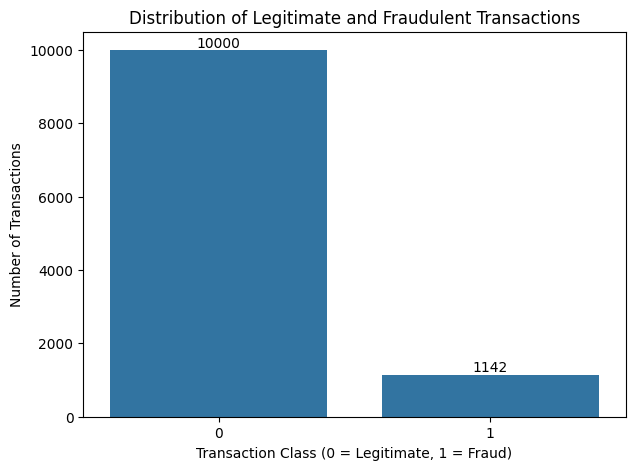

In [47]:
# Visualize target class distribution

plt.figure(figsize=(7, 5))

ax = sns.countplot(data=df, x='isFraud')

plt.title('Distribution of Legitimate and Fraudulent Transactions')
plt.xlabel('Transaction Class (0 = Legitimate, 1 = Fraud)')
plt.ylabel('Number of Transactions')

for container in ax.containers:
    ax.bar_label(container)

plt.show()

### Observation

The target variable is imbalanced, with legitimate transactions forming the majority of observations and fraudulent transactions representing a smaller proportion of the dataset.

Therefore, accuracy alone may not be sufficient for evaluating model performance. Metrics such as Precision, Recall, F1-Score and ROC-AUC will also be considered.

Class imbalance handling techniques will be evaluated during the modeling stage.

# Exploratory Data Analysis (EDA)

The purpose of Exploratory Data Analysis is to understand transaction behaviour and identify patterns associated with fraudulent transactions.

The analysis focuses on:

- Distribution of transaction types
- Fraud occurrence across transaction types
- Transaction amount patterns
- Fraudulent vs legitimate transaction amounts
- Transaction behaviour over time
- Origin and destination account balances
- Balance inconsistencies
- Financial exposure associated with fraud

The insights obtained from EDA will guide feature engineering and model development.

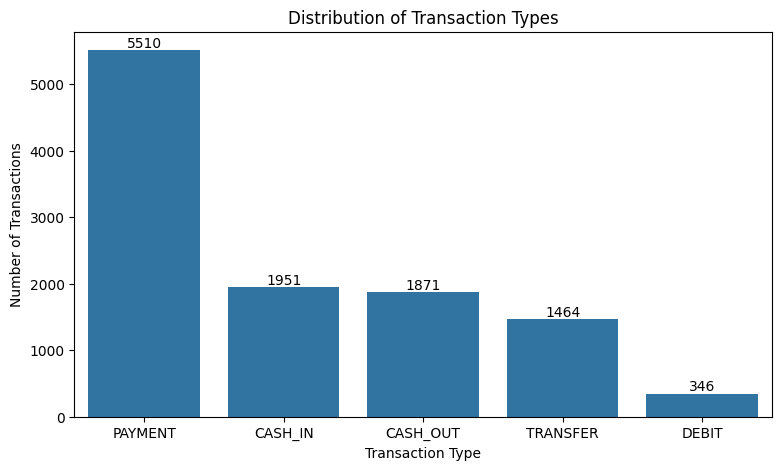

,count
type,
PAYMENT,5510
CASH_IN,1951
CASH_OUT,1871
TRANSFER,1464
DEBIT,346


In [48]:
# Transaction type distribution

transaction_type_counts = df['type'].value_counts()

plt.figure(figsize=(9, 5))

ax = sns.countplot(
    data=df,
    x='type',
    order=transaction_type_counts.index
)

plt.title('Distribution of Transaction Types')
plt.xlabel('Transaction Type')
plt.ylabel('Number of Transactions')

for container in ax.containers:
    ax.bar_label(container)

plt.show()

transaction_type_counts

### Observation

The dataset contains five transaction categories: CASH_IN, CASH_OUT, DEBIT, PAYMENT and TRANSFER.

The transaction types occur at different frequencies. Transaction volume alone, however, does not indicate fraud risk. Therefore, the relationship between transaction type and fraud status is examined next.

In [49]:
# Fraud counts by transaction type

fraud_by_type = pd.crosstab(
    df['type'],
    df['isFraud']
)

fraud_by_type.columns = ['Legitimate', 'Fraud']

fraud_by_type

,Legitimate,Fraud
type,,
CASH_IN,1951,0
CASH_OUT,1293,578
DEBIT,346,0
PAYMENT,5510,0
TRANSFER,900,564


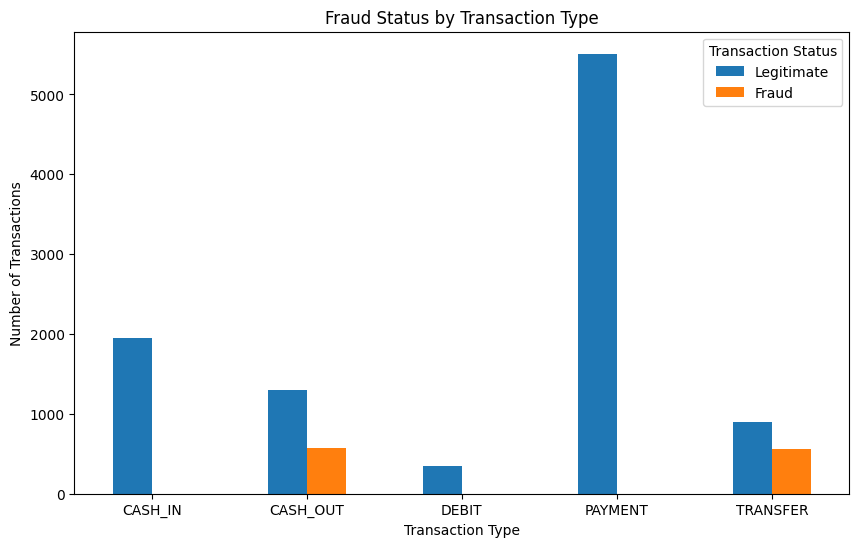

In [50]:
fraud_by_type.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Fraud Status by Transaction Type')
plt.xlabel('Transaction Type')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=0)
plt.legend(title='Transaction Status')

plt.show()

In [51]:
# Calculate fraud statistics by transaction type

fraud_type_summary = df.groupby('type').agg(
    Total_Transactions=('isFraud', 'count'),
    Fraud_Transactions=('isFraud', 'sum')
)

fraud_type_summary['Legitimate_Transactions'] = (
    fraud_type_summary['Total_Transactions']
    - fraud_type_summary['Fraud_Transactions']
)

fraud_type_summary['Fraud_Rate_%'] = (
    fraud_type_summary['Fraud_Transactions']
    / fraud_type_summary['Total_Transactions']
) * 100

fraud_type_summary = fraud_type_summary.sort_values(
    'Fraud_Rate_%',
    ascending=False
)

fraud_type_summary

,Total_Transactions,Fraud_Transactions,Legitimate_Transactions,Fraud_Rate_%
type,,,,
TRANSFER,1464,564,900,38.52
CASH_OUT,1871,578,1293,30.89
CASH_IN,1951,0,1951,0.00
DEBIT,346,0,346,0.00
PAYMENT,5510,0,5510,0.00


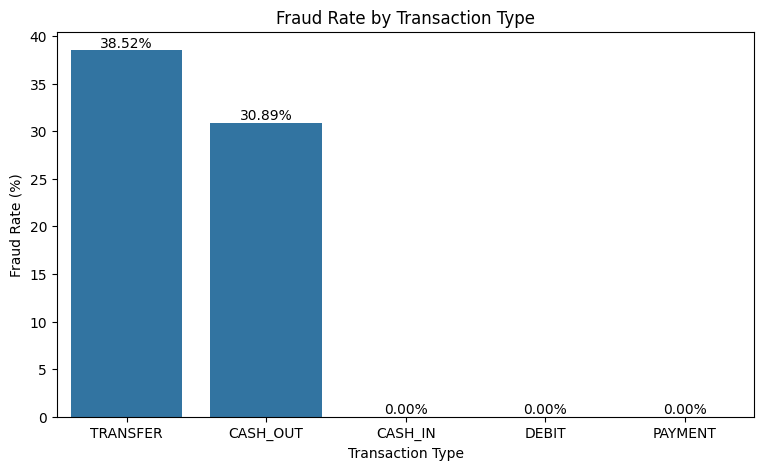

In [52]:
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=fraud_type_summary.reset_index(),
    x='type',
    y='Fraud_Rate_%'
)

plt.title('Fraud Rate by Transaction Type')
plt.xlabel('Transaction Type')
plt.ylabel('Fraud Rate (%)')

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%')

plt.show()

### Observation

Fraud is not distributed equally across transaction types. Fraudulent transactions are concentrated in specific transaction categories, particularly TRANSFER and CASH_OUT transactions in this dataset.

This pattern is consistent with the fraud mechanism described for the dataset, where fraudulent agents attempt to transfer funds from compromised accounts and subsequently cash them out.

Transaction type therefore appears to be an important candidate predictor for the fraud detection model.

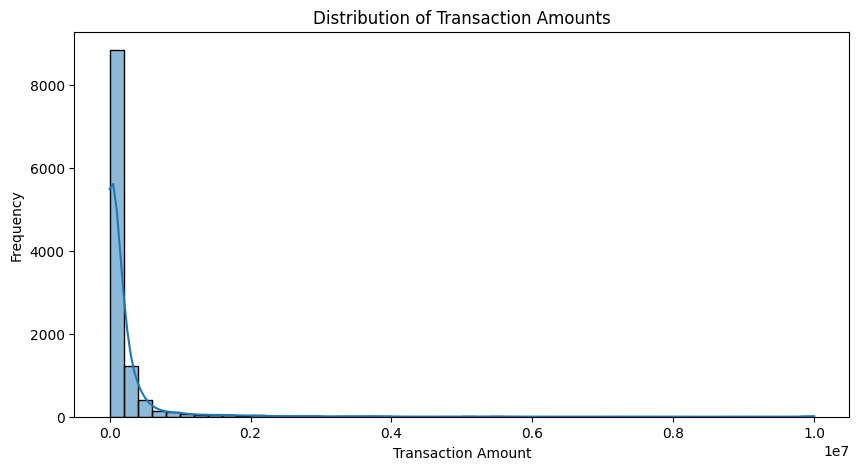

In [53]:
# Transaction amount distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='amount',
    bins=50,
    kde=True
)

plt.title('Distribution of Transaction Amounts')
plt.xlabel('Transaction Amount')
plt.ylabel('Frequency')

plt.show()

In [54]:
# Transaction amount statistics

df['amount'].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

,amount
count,"11,142.00"
mean,"213,191.49"
std,"760,065.01"
min,2.39
25%,"4,946.62"
50%,"16,761.26"
75%,"154,336.58"
90%,"395,675.15"
95%,"810,039.19"
99%,"3,606,943.31"


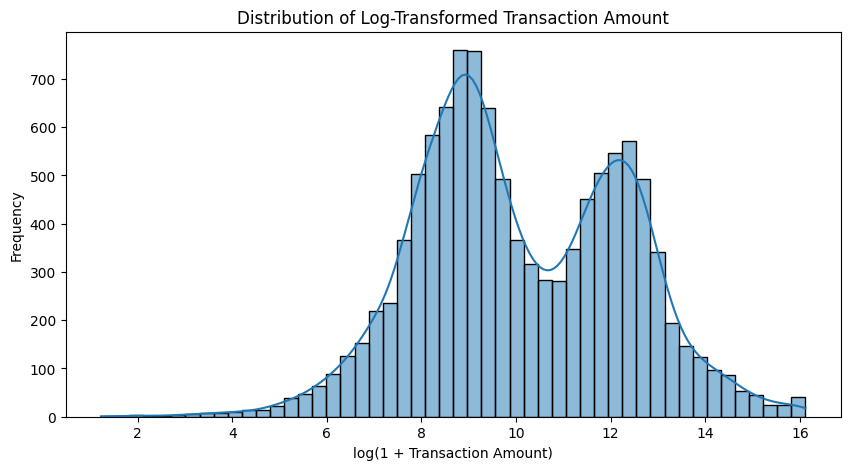

In [55]:
# Log transform for visualization
# log1p safely handles zero values

df['log_amount'] = np.log1p(df['amount'])

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='log_amount',
    bins=50,
    kde=True
)

plt.title('Distribution of Log-Transformed Transaction Amount')
plt.xlabel('log(1 + Transaction Amount)')
plt.ylabel('Frequency')

plt.show()

In [56]:
amount_by_fraud = df.groupby('isFraud')['amount'].agg(
    ['count', 'mean', 'median', 'min', 'max']
)

amount_by_fraud.index = ['Legitimate', 'Fraud']

amount_by_fraud

,count,mean,median,min,max
Legitimate,10000,"101,339.73","12,725.24",2.39,"3,776,389.09"
Fraud,1142,"1,192,628.93","353,179.45",119.00,"10,000,000.00"


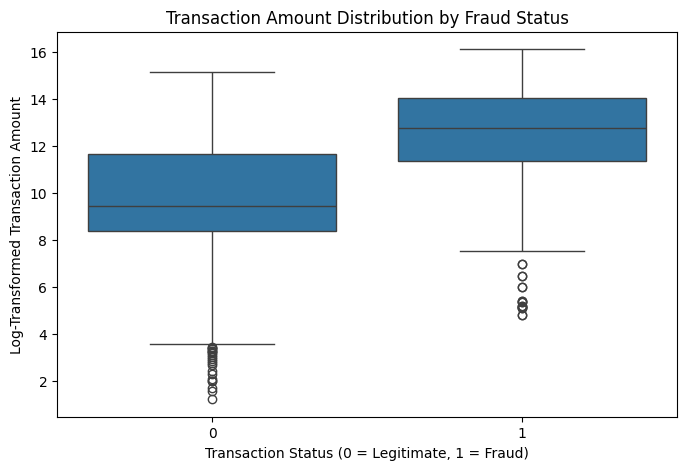

In [57]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='isFraud',
    y='log_amount'
)

plt.title('Transaction Amount Distribution by Fraud Status')
plt.xlabel('Transaction Status (0 = Legitimate, 1 = Fraud)')
plt.ylabel('Log-Transformed Transaction Amount')

plt.show()

### Observation

The transaction amount distribution differs between legitimate and fraudulent transactions.

Because transaction amounts are strongly skewed, a log transformation was used for clearer visualization. The relationship between transaction amount and fraud status suggests that transaction value may provide useful predictive information.

However, transaction amount alone should not be treated as sufficient evidence of fraud.

In [58]:
financial_summary = df.groupby('isFraud').agg(
    Transactions=('amount', 'count'),
    Total_Amount=('amount', 'sum'),
    Average_Amount=('amount', 'mean'),
    Median_Amount=('amount', 'median')
)

financial_summary.index = ['Legitimate', 'Fraud']

financial_summary

,Transactions,Total_Amount,Average_Amount,Median_Amount
Legitimate,10000,"1,013,397,286.38","101,339.73","12,725.24"
Fraud,1142,"1,361,982,240.43","1,192,628.93","353,179.45"


In [59]:
total_fraud_amount = df.loc[
    df['isFraud'] == 1,
    'amount'
].sum()

print(f"Total value of fraudulent transactions: {total_fraud_amount:,.2f}")

Total value of fraudulent transactions: 1,361,982,240.43


In [60]:
fraud_amount_by_type = (
    df[df['isFraud'] == 1]
    .groupby('type')
    .agg(
        Fraud_Transactions=('isFraud', 'count'),
        Total_Fraud_Amount=('amount', 'sum'),
        Average_Fraud_Amount=('amount', 'mean')
    )
    .sort_values('Total_Fraud_Amount', ascending=False)
)

fraud_amount_by_type

,Fraud_Transactions,Total_Fraud_Amount,Average_Fraud_Amount
type,,,
TRANSFER,564,"681,598,379.85","1,208,507.77"
CASH_OUT,578,"680,383,860.58","1,177,134.71"


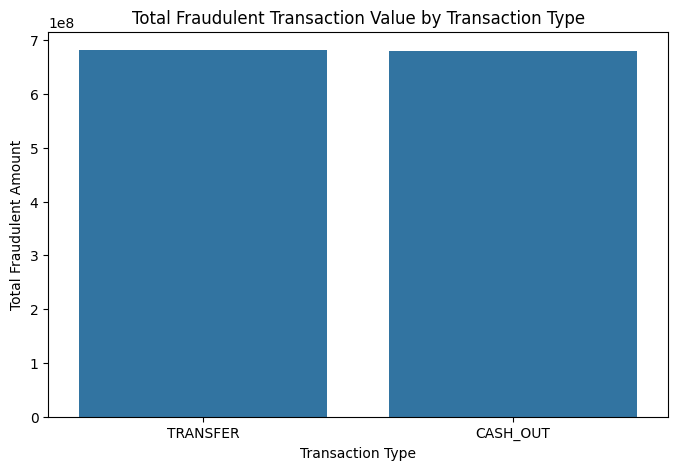

In [61]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=fraud_amount_by_type.reset_index(),
    x='type',
    y='Total_Fraud_Amount'
)

plt.title('Total Fraudulent Transaction Value by Transaction Type')
plt.xlabel('Transaction Type')
plt.ylabel('Total Fraudulent Amount')

plt.show()

In [62]:
fraud_by_step = df.groupby('step').agg(
    Total_Transactions=('isFraud', 'count'),
    Fraud_Transactions=('isFraud', 'sum')
)

fraud_by_step['Fraud_Rate_%'] = (
    fraud_by_step['Fraud_Transactions']
    / fraud_by_step['Total_Transactions']
) * 100

fraud_by_step.head()

,Total_Transactions,Fraud_Transactions,Fraud_Rate_%
step,,,
1,2708,16,0.59
2,1014,8,0.79
3,552,4,0.72
4,565,10,1.77
5,665,6,0.90


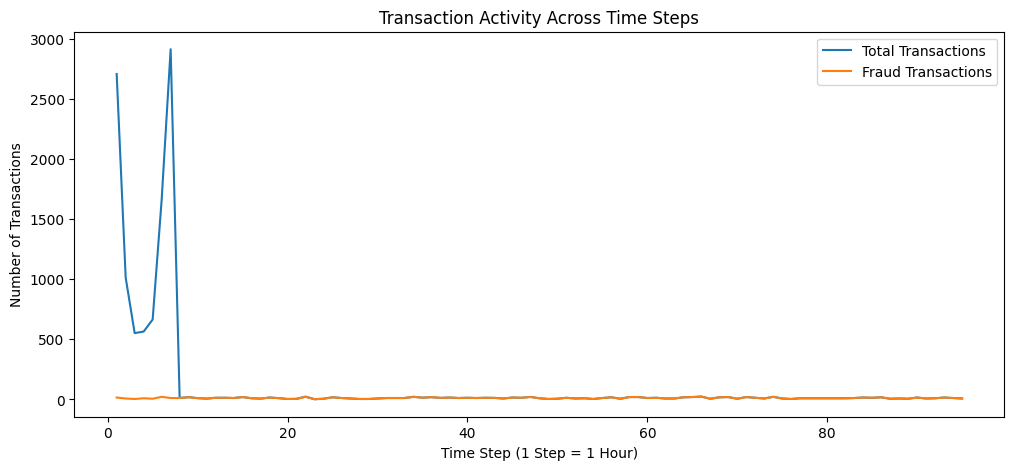

In [63]:
plt.figure(figsize=(12, 5))

plt.plot(
    fraud_by_step.index,
    fraud_by_step['Total_Transactions'],
    label='Total Transactions'
)

plt.plot(
    fraud_by_step.index,
    fraud_by_step['Fraud_Transactions'],
    label='Fraud Transactions'
)

plt.title('Transaction Activity Across Time Steps')
plt.xlabel('Time Step (1 Step = 1 Hour)')
plt.ylabel('Number of Transactions')
plt.legend()

plt.show()

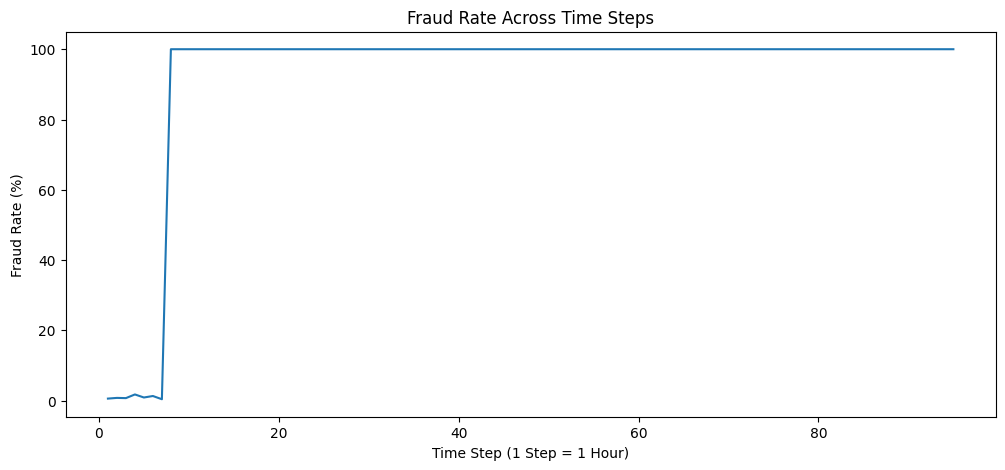

In [64]:
plt.figure(figsize=(12, 5))

plt.plot(
    fraud_by_step.index,
    fraud_by_step['Fraud_Rate_%']
)

plt.title('Fraud Rate Across Time Steps')
plt.xlabel('Time Step (1 Step = 1 Hour)')
plt.ylabel('Fraud Rate (%)')

plt.show()

In [65]:
df['hour_in_cycle'] = df['step'] % 24

In [66]:
origin_balance_summary = df.groupby('isFraud')[
    ['oldbalanceOrg', 'newbalanceOrig']
].median()

origin_balance_summary.index = ['Legitimate', 'Fraud']

origin_balance_summary

,oldbalanceOrg,newbalanceOrig
Legitimate,"21,324.50","10,624.75"
Fraud,"348,705.15",0.00


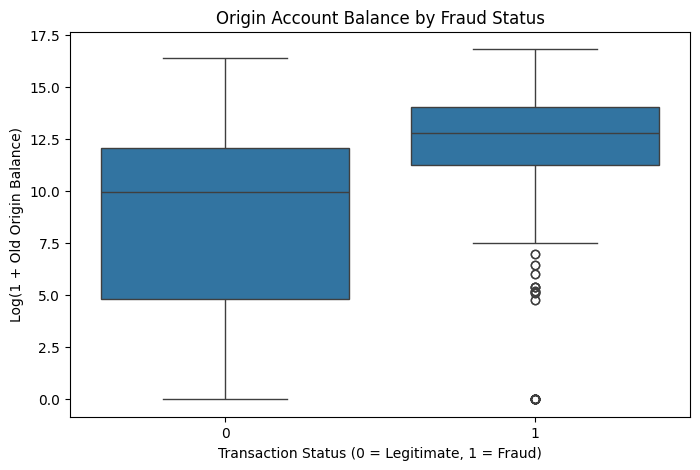

In [67]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='isFraud',
    y=np.log1p(df['oldbalanceOrg'])
)

plt.title('Origin Account Balance by Fraud Status')
plt.xlabel('Transaction Status (0 = Legitimate, 1 = Fraud)')
plt.ylabel('Log(1 + Old Origin Balance)')

plt.show()

In [68]:
df['origin_balance_change'] = (
    df['oldbalanceOrg'] - df['newbalanceOrig']
)

df[
    [
        'type',
        'amount',
        'oldbalanceOrg',
        'newbalanceOrig',
        'origin_balance_change',
        'isFraud'
    ]
].head(10)

,type,amount,oldbalanceOrg,newbalanceOrig,origin_balance_change,isFraud
0,TRANSFER,181.00,181.00,0.00,181.00,1
1,CASH_OUT,181.00,181.00,0.00,181.00,1
2,TRANSFER,"2,806.00","2,806.00",0.00,"2,806.00",1
3,CASH_OUT,"2,806.00","2,806.00",0.00,"2,806.00",1
4,TRANSFER,"20,128.00","20,128.00",0.00,"20,128.00",1
5,CASH_OUT,"20,128.00","20,128.00",0.00,"20,128.00",1
6,CASH_OUT,"416,001.33",0.00,0.00,0.00,1
7,TRANSFER,"1,277,212.77","1,277,212.77",0.00,"1,277,212.77",1
8,CASH_OUT,"1,277,212.77","1,277,212.77",0.00,"1,277,212.77",1
9,TRANSFER,"35,063.63","35,063.63",0.00,"35,063.63",1


In [69]:
df.groupby('isFraud')[
    'origin_balance_change'
].describe()

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,"10,000.00","-24,808.18","99,637.64","-1,030,100.15",0.00,538.59,"5,713.81","2,317,408.88"
1,"1,142.00","1,184,691.90","2,033,327.68",0.00,"77,837.08","348,705.15","1,217,448.66","10,038,991.68"


In [70]:
df['origin_balance_error'] = (
    df['oldbalanceOrg']
    - df['amount']
    - df['newbalanceOrig']
)

df.groupby('isFraud')[
    'origin_balance_error'
].agg(['mean', 'median', 'std', 'min', 'max'])

,mean,median,std,min,max
isFraud,,,,,
0,"-126,147.91","-5,573.72","263,813.43","-3,776,389.09",0.01
1,"-7,937.03",0.00,"85,459.67","-1,933,920.80","38,991.68"


In [71]:
df['destination_balance_change'] = (
    df['newbalanceDest'] - df['oldbalanceDest']
)

df.groupby('isFraud')[
    'destination_balance_change'
].describe()

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,"10,000.00","168,010.62","1,039,985.98","-13,100,000.00",0.00,0.00,0.00,"18,299,820.00"
1,"1,142.00","625,074.35","1,592,163.53","-315,226.07",0.00,"3,733.04","378,567.49","10,026,725.16"


In [72]:
df['destination_balance_error'] = (
    df['oldbalanceDest']
    + df['amount']
    - df['newbalanceDest']
)

df.groupby('isFraud')[
    'destination_balance_error'
].agg(['mean', 'median', 'std', 'min', 'max'])

,mean,median,std,min,max
isFraud,,,,,
0,"-66,670.89","6,605.92","985,282.45","-17,919,963.77","13,230,407.77"
1,"567,554.59","9,439.94","1,593,694.75","-8,875,516.29","10,000,000.00"


In [73]:
df['is_merchant_dest'] = (
    df['nameDest']
    .astype(str)
    .str.startswith('M')
    .astype(int)
)

df['is_merchant_dest'].value_counts()

,count
is_merchant_dest,
0,5632
1,5510


In [74]:
merchant_fraud = pd.crosstab(
    df['is_merchant_dest'],
    df['isFraud'],
    normalize='index'
) * 100

merchant_fraud.columns = ['Legitimate_%', 'Fraud_%']

merchant_fraud

,Legitimate_%,Fraud_%
is_merchant_dest,,
0,79.72,20.28
1,100.00,0.00


In [75]:
fraud_origin_counts = (
    df[df['isFraud'] == 1]['nameOrig']
    .value_counts()
)

fraud_origin_counts.head(10)

,count
nameOrig,
C409531429,1
C1305486145,1
C840083671,1
C1420196421,1
C2101527076,1
C137533655,1
C824268591,1
C708686257,1
C395839623,1


In [76]:
print(
    "Unique origin accounts:",
    df['nameOrig'].nunique()
)

print(
    "Unique fraudulent origin accounts:",
    df.loc[df['isFraud'] == 1, 'nameOrig'].nunique()
)

print(
    "Repeated fraudulent origin accounts:",
    (fraud_origin_counts > 1).sum()
)

Unique origin accounts: 11142
Unique fraudulent origin accounts: 1142
Repeated fraudulent origin accounts: 0


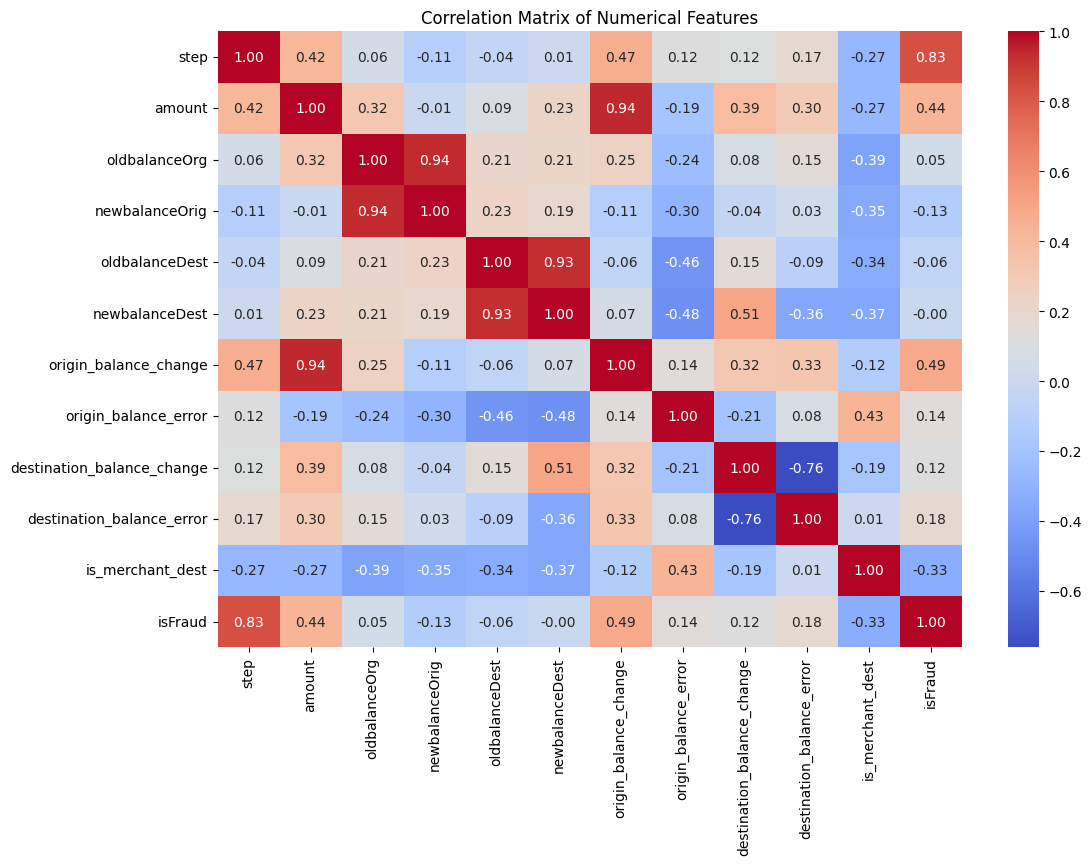

In [77]:
numeric_columns = [
    'step',
    'amount',
    'oldbalanceOrg',
    'newbalanceOrig',
    'oldbalanceDest',
    'newbalanceDest',
    'origin_balance_change',
    'origin_balance_error',
    'destination_balance_change',
    'destination_balance_error',
    'is_merchant_dest',
    'isFraud'
]

correlation_matrix = df[numeric_columns].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm'
)

plt.title('Correlation Matrix of Numerical Features')

plt.show()

In [78]:
fraud_correlations = (
    correlation_matrix['isFraud']
    .drop('isFraud')
    .sort_values(ascending=False)
)

fraud_correlations

,isFraud
step,0.83
origin_balance_change,0.49
amount,0.44
destination_balance_error,0.18
origin_balance_error,0.14
destination_balance_change,0.12
oldbalanceOrg,0.05
newbalanceDest,-0.00
oldbalanceDest,-0.06
newbalanceOrig,-0.13


## EDA Summary

The exploratory analysis examined transaction categories, transaction values, time steps, account balances, destination characteristics and fraud distribution.

Preliminary analysis indicates that fraud is not uniformly distributed across transaction types and that transaction amount and account balance behaviour may contain useful predictive information.

The EDA also highlights important dataset-specific considerations, including unavailable destination balance information for merchant accounts.

These findings will be used to guide feature engineering and machine learning model development in the next stage.

In [79]:
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,log_amount,hour_in_cycle,origin_balance_change,origin_balance_error,destination_balance_change,destination_balance_error,is_merchant_dest
0,1,TRANSFER,181.00,C1305486145,181.00,0.00,C553264065,0.00,0.00,1,5.20,1,181.00,0.00,0.00,181.00,0
1,1,CASH_OUT,181.00,C840083671,181.00,0.00,C38997010,"21,182.00",0.00,1,5.20,1,181.00,0.00,"-21,182.00","21,363.00",0
2,1,TRANSFER,"2,806.00",C1420196421,"2,806.00",0.00,C972765878,0.00,0.00,1,7.94,1,"2,806.00",0.00,0.00,"2,806.00",0
3,1,CASH_OUT,"2,806.00",C2101527076,"2,806.00",0.00,C1007251739,"26,202.00",0.00,1,7.94,1,"2,806.00",0.00,"-26,202.00","29,008.00",0
4,1,TRANSFER,"20,128.00",C137533655,"20,128.00",0.00,C1848415041,0.00,0.00,1,9.91,1,"20,128.00",0.00,0.00,"20,128.00",0


Feature Engineering and Data Preprocessing

Feature engineering transforms the available transaction information into variables that may help machine learning models distinguish fraudulent from legitimate transactions.

Based on the exploratory analysis, additional features are created from transaction amounts, account balances, transaction type, time step and destination-account characteristics.

Special attention is given to preventing data leakage and ensuring that preprocessing steps are learned only from the training data.

In [81]:
# Create a separate copy for machine learning

model_df = df.copy()

print("Modeling dataset shape:", model_df.shape)

Modeling dataset shape: (11142, 17)


In [82]:
# Derive hour within a 24-hour cycle

model_df['hour_in_cycle'] = model_df['step'] % 24

model_df[['step', 'hour_in_cycle']].head(10)

,step,hour_in_cycle
0,1,1
1,1,1
2,1,1
3,1,1
4,1,1
5,1,1
6,1,1
7,1,1
8,1,1
9,1,1


In [83]:
# Log-transform transaction amount

model_df['log_amount'] = np.log1p(model_df['amount'])

model_df[['amount', 'log_amount']].head()

,amount,log_amount
0,181.00,5.20
1,181.00,5.20
2,"2,806.00",7.94
3,"2,806.00",7.94
4,"20,128.00",9.91


In [84]:
# Difference between expected and recorded origin balance

model_df['origin_balance_error'] = (
    model_df['oldbalanceOrg']
    - model_df['amount']
    - model_df['newbalanceOrig']
)

In [85]:
model_df['destination_balance_change'] = (
    model_df['newbalanceDest']
    - model_df['oldbalanceDest']
)

In [86]:
model_df['destination_balance_error'] = (
    model_df['oldbalanceDest']
    + model_df['amount']
    - model_df['newbalanceDest']
)

In [87]:
model_df['is_merchant_dest'] = (
    model_df['nameDest']
    .astype(str)
    .str.startswith('M')
    .astype(int)
)

model_df['is_merchant_dest'].value_counts()

,count
is_merchant_dest,
0,5632
1,5510


In [88]:
# Zero-balance indicators

model_df['origin_new_balance_zero'] = (
    model_df['newbalanceOrig'] == 0
).astype(int)

model_df['destination_old_balance_zero'] = (
    model_df['oldbalanceDest'] == 0
).astype(int)

In [89]:
pd.crosstab(
    model_df['origin_new_balance_zero'],
    model_df['isFraud'],
    normalize='index'
) * 100

isFraud,0,1
origin_new_balance_zero,,
0,99.85,0.15
1,78.05,21.95


In [90]:
model_df['amount_to_oldbalance_ratio'] = np.where(
    model_df['oldbalanceOrg'] > 0,
    model_df['amount'] / model_df['oldbalanceOrg'],
    0
)

In [91]:
model_df['amount_to_oldbalance_ratio'] = (
    model_df['amount_to_oldbalance_ratio']
    .replace([np.inf, -np.inf], 0)
)

In [92]:
model_df['amount_to_oldbalance_ratio'].describe()

,amount_to_oldbalance_ratio
count,"11,142.00"
mean,12.71
std,250.51
min,0.00
25%,0.00
50%,0.09
75%,1.00
max,"21,761.03"


In [93]:
engineered_features = [
    'hour_in_cycle',
    'log_amount',
    'origin_balance_change',
    'origin_balance_error',
    'destination_balance_change',
    'destination_balance_error',
    'is_merchant_dest',
    'origin_new_balance_zero',
    'destination_old_balance_zero',
    'amount_to_oldbalance_ratio'
]

model_df[engineered_features].head()

,hour_in_cycle,log_amount,origin_balance_change,origin_balance_error,destination_balance_change,destination_balance_error,is_merchant_dest,origin_new_balance_zero,destination_old_balance_zero,amount_to_oldbalance_ratio
0,1,5.20,181.00,0.00,0.00,181.00,0,1,1,1.00
1,1,5.20,181.00,0.00,"-21,182.00","21,363.00",0,1,0,1.00
2,1,7.94,"2,806.00",0.00,0.00,"2,806.00",0,1,1,1.00
3,1,7.94,"2,806.00",0.00,"-26,202.00","29,008.00",0,1,0,1.00
4,1,9.91,"20,128.00",0.00,0.00,"20,128.00",0,1,1,1.00


In [94]:
print(
    "Missing values in engineered features:",
    model_df[engineered_features].isnull().sum().sum()
)

print(
    "Infinite values:",
    np.isinf(
        model_df[engineered_features]
        .select_dtypes(include=np.number)
    ).sum().sum()
)

Missing values in engineered features: 0
Infinite values: 0


Treatment of Account Identifiers

`nameOrig` and `nameDest` are account identifiers rather than ordinary categorical variables.

Direct one-hot encoding of these columns would create a very high-dimensional feature space and could encourage the model to memorize specific account IDs rather than learn general fraud patterns.

Therefore, the raw account identifiers are excluded from the predictive model.

Useful information derived from the identifiers, such as whether the destination represents a merchant, is retained through engineered features.

In [95]:
features = [
    'step',
    'type',
    'amount',
    'oldbalanceOrg',
    'newbalanceOrig',
    'oldbalanceDest',
    'newbalanceDest',
    'hour_in_cycle',
    'log_amount',
    'origin_balance_change',
    'origin_balance_error',
    'destination_balance_change',
    'destination_balance_error',
    'is_merchant_dest',
    'origin_new_balance_zero',
    'destination_old_balance_zero',
    'amount_to_oldbalance_ratio'
]

X = model_df[features]
y = model_df['isFraud']

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

Feature matrix shape: (11142, 17)
Target shape: (11142,)


In [96]:
display(X.head())

print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget percentage:")
print((y.value_counts(normalize=True) * 100).round(2))

,step,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,hour_in_cycle,log_amount,origin_balance_change,origin_balance_error,destination_balance_change,destination_balance_error,is_merchant_dest,origin_new_balance_zero,destination_old_balance_zero,amount_to_oldbalance_ratio
0,1,TRANSFER,181.00,181.00,0.00,0.00,0.00,1,5.20,181.00,0.00,0.00,181.00,0,1,1,1.00
1,1,CASH_OUT,181.00,181.00,0.00,"21,182.00",0.00,1,5.20,181.00,0.00,"-21,182.00","21,363.00",0,1,0,1.00
2,1,TRANSFER,"2,806.00","2,806.00",0.00,0.00,0.00,1,7.94,"2,806.00",0.00,0.00,"2,806.00",0,1,1,1.00
3,1,CASH_OUT,"2,806.00","2,806.00",0.00,"26,202.00",0.00,1,7.94,"2,806.00",0.00,"-26,202.00","29,008.00",0,1,0,1.00
4,1,TRANSFER,"20,128.00","20,128.00",0.00,0.00,0.00,1,9.91,"20,128.00",0.00,0.00,"20,128.00",0,1,1,1.00



Target distribution:
isFraud
0    10000
1     1142
Name: count, dtype: int64

Target percentage:
isFraud
0   89.75
1   10.25
Name: proportion, dtype: float64


In [97]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y    #we want approximately the same fraud proportion in both sets
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Training set: (8913, 17)
Test set: (2229, 17)


In [98]:
print("Training class distribution:")
print(
    (y_train.value_counts(normalize=True) * 100)
    .round(2)
)

print("\nTest class distribution:")
print(
    (y_test.value_counts(normalize=True) * 100)
    .round(2)
)

Training class distribution:
isFraud
0   89.75
1   10.25
Name: proportion, dtype: float64

Test class distribution:
isFraud
0   89.77
1   10.23
Name: proportion, dtype: float64


Prevention of Data Leakage

The dataset was divided into training and testing sets before applying any resampling technique.

SMOTE will only be applied to the training data. The test dataset will remain untouched so that model performance is evaluated on the original class distribution.

Applying SMOTE before the train-test split could allow synthetic observations derived from the same underlying samples to influence both training and testing, resulting in overly optimistic model performance.

In [99]:
categorical_features = ['type']

numerical_features = [
    col for col in features
    if col not in categorical_features
]

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

Categorical features:
['type']

Numerical features:
['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'hour_in_cycle', 'log_amount', 'origin_balance_change', 'origin_balance_error', 'destination_balance_change', 'destination_balance_error', 'is_merchant_dest', 'origin_new_balance_zero', 'destination_old_balance_zero', 'amount_to_oldbalance_ratio']


In [100]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        (
            'num',
            StandardScaler(),
            numerical_features
        ),
        (
            'cat',
            OneHotEncoder(
                handle_unknown='ignore'
            ),
            categorical_features
        )
    ]
)

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


In [101]:
!pip install -q imbalanced-learn

In [102]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

print("SMOTE libraries imported successfully.")

SMOTE libraries imported successfully.


In [103]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

In [104]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

logistic_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),

        ('classifier', LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ]
)

logistic_pipeline.fit(
    X_train,
    y_train
)

print("Logistic Regression training completed.")

Logistic Regression training completed.


In [105]:
y_pred_lr = logistic_pipeline.predict(X_test)

y_prob_lr = logistic_pipeline.predict_proba(
    X_test
)[:, 1]

In [106]:
lr_accuracy = accuracy_score(
    y_test,
    y_pred_lr
)

lr_precision = precision_score(
    y_test,
    y_pred_lr
)

lr_recall = recall_score(
    y_test,
    y_pred_lr
)

lr_f1 = f1_score(
    y_test,
    y_pred_lr
)

lr_roc_auc = roc_auc_score(
    y_test,
    y_prob_lr
)

print(f"Accuracy : {lr_accuracy:.4f}")
print(f"Precision: {lr_precision:.4f}")
print(f"Recall   : {lr_recall:.4f}")
print(f"F1 Score : {lr_f1:.4f}")
print(f"ROC-AUC  : {lr_roc_auc:.4f}")

Accuracy : 0.9946
Precision: 1.0000
Recall   : 0.9474
F1 Score : 0.9730
ROC-AUC  : 0.9918


In [107]:
print(
    classification_report(
        y_test,
        y_pred_lr,
        target_names=[
            'Legitimate',
            'Fraud'
        ]
    )
)

              precision    recall  f1-score   support

  Legitimate       0.99      1.00      1.00      2001
       Fraud       1.00      0.95      0.97       228

    accuracy                           0.99      2229
   macro avg       1.00      0.97      0.98      2229
weighted avg       0.99      0.99      0.99      2229



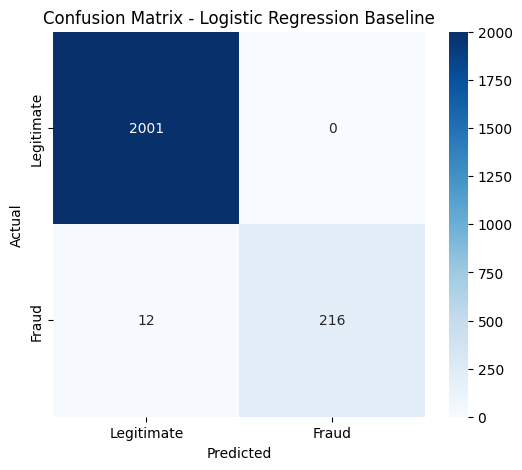

In [108]:
cm_lr = confusion_matrix(
    y_test,
    y_pred_lr
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=[
        'Legitimate',
        'Fraud'
    ],
    yticklabels=[
        'Legitimate',
        'Fraud'
    ]
)

plt.title(
    'Confusion Matrix - Logistic Regression Baseline'
)

plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

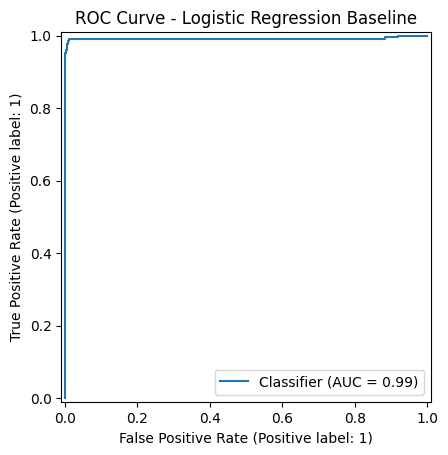

In [109]:
  RocCurveDisplay.from_predictions(
    y_test,
    y_prob_lr
)

plt.title(
    'ROC Curve - Logistic Regression Baseline'
)

plt.show()

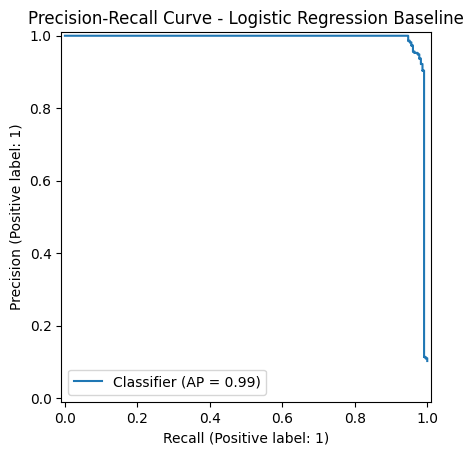

In [110]:
PrecisionRecallDisplay.from_predictions(
    y_test,
    y_prob_lr
)

plt.title(
    'Precision-Recall Curve - Logistic Regression Baseline'
)

plt.show()

In [111]:
model_results = []

model_results.append({
    'Model': 'Logistic Regression',
    'Sampling': 'Original',
    'Accuracy': lr_accuracy,
    'Precision': lr_precision,
    'Recall': lr_recall,
    'F1': lr_f1,
    'ROC_AUC': lr_roc_auc
})

pd.DataFrame(model_results)

,Model,Sampling,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,Original,0.99,1.00,0.95,0.97,0.99


In [112]:
# ==========================================
# LOGISTIC REGRESSION WITH CLASS WEIGHT
# ==========================================

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

logistic_weighted_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),

        ('classifier', LogisticRegression(
            class_weight='balanced',
            max_iter=2000,
            random_state=42
        ))
    ]
)

logistic_weighted_pipeline.fit(X_train, y_train)

print("Class-weighted Logistic Regression trained successfully.")

Class-weighted Logistic Regression trained successfully.


In [113]:
y_pred_lr_weighted = logistic_weighted_pipeline.predict(X_test)

y_prob_lr_weighted = logistic_weighted_pipeline.predict_proba(
    X_test
)[:, 1]

In [114]:
lrw_accuracy = accuracy_score(y_test, y_pred_lr_weighted)
lrw_precision = precision_score(y_test, y_pred_lr_weighted)
lrw_recall = recall_score(y_test, y_pred_lr_weighted)
lrw_f1 = f1_score(y_test, y_pred_lr_weighted)
lrw_roc_auc = roc_auc_score(y_test, y_prob_lr_weighted)

print("Logistic Regression - Class Weighted")
print("-" * 45)

print(f"Accuracy : {lrw_accuracy:.4f}")
print(f"Precision: {lrw_precision:.4f}")
print(f"Recall   : {lrw_recall:.4f}")
print(f"F1 Score : {lrw_f1:.4f}")
print(f"ROC-AUC  : {lrw_roc_auc:.4f}")

Logistic Regression - Class Weighted
---------------------------------------------
Accuracy : 0.9915
Precision: 0.9372
Recall   : 0.9825
F1 Score : 0.9593
ROC-AUC  : 0.9948


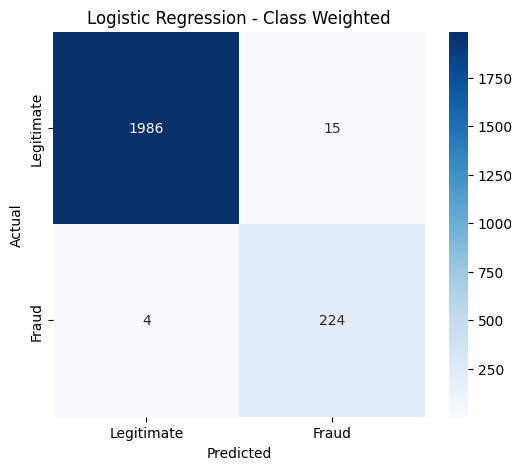

In [115]:
cm_lrw = confusion_matrix(
    y_test,
    y_pred_lr_weighted
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_lrw,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Legitimate', 'Fraud'],
    yticklabels=['Legitimate', 'Fraud']
)

plt.title('Logistic Regression - Class Weighted')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

In [116]:
smote_logistic_pipeline = ImbPipeline(
    steps=[
        ('preprocessor', preprocessor),

        ('smote', SMOTE(
            random_state=42
        )),

        ('classifier', LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ]
)

smote_logistic_pipeline.fit(
    X_train,
    y_train
)

print("SMOTE Logistic Regression trained successfully.")

SMOTE Logistic Regression trained successfully.


In [117]:
y_pred_lr_smote = smote_logistic_pipeline.predict(
    X_test
)

y_prob_lr_smote = smote_logistic_pipeline.predict_proba(
    X_test
)[:, 1]

In [118]:
lrs_accuracy = accuracy_score(y_test, y_pred_lr_smote)
lrs_precision = precision_score(y_test, y_pred_lr_smote)
lrs_recall = recall_score(y_test, y_pred_lr_smote)
lrs_f1 = f1_score(y_test, y_pred_lr_smote)
lrs_roc_auc = roc_auc_score(y_test, y_prob_lr_smote)

print("Logistic Regression - SMOTE")
print("-" * 45)

print(f"Accuracy : {lrs_accuracy:.4f}")
print(f"Precision: {lrs_precision:.4f}")
print(f"Recall   : {lrs_recall:.4f}")
print(f"F1 Score : {lrs_f1:.4f}")
print(f"ROC-AUC  : {lrs_roc_auc:.4f}")

Logistic Regression - SMOTE
---------------------------------------------
Accuracy : 0.9915
Precision: 0.9372
Recall   : 0.9825
F1 Score : 0.9593
ROC-AUC  : 0.9925


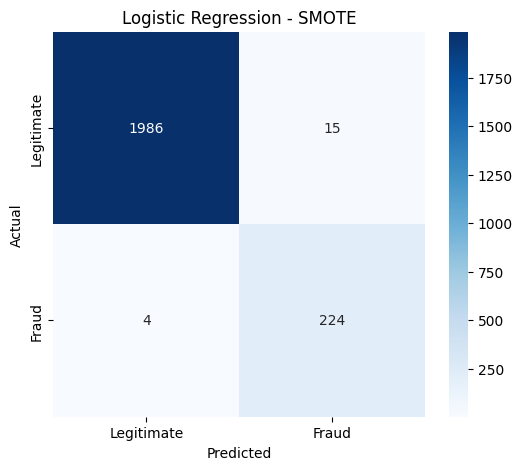

In [119]:
cm_lrs = confusion_matrix(
    y_test,
    y_pred_lr_smote
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_lrs,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Legitimate', 'Fraud'],
    yticklabels=['Legitimate', 'Fraud']
)

plt.title('Logistic Regression - SMOTE')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

In [120]:
model_results.append({
    'Model': 'Logistic Regression',
    'Sampling': 'Class Weight',
    'Accuracy': lrw_accuracy,
    'Precision': lrw_precision,
    'Recall': lrw_recall,
    'F1': lrw_f1,
    'ROC_AUC': lrw_roc_auc
})

model_results.append({
    'Model': 'Logistic Regression',
    'Sampling': 'SMOTE',
    'Accuracy': lrs_accuracy,
    'Precision': lrs_precision,
    'Recall': lrs_recall,
    'F1': lrs_f1,
    'ROC_AUC': lrs_roc_auc
})

results_df = pd.DataFrame(model_results)

results_df.round(4)

,Model,Sampling,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,Original,0.99,1.00,0.95,0.97,0.99
1,Logistic Regression,Class Weight,0.99,0.94,0.98,0.96,0.99
2,Logistic Regression,SMOTE,0.99,0.94,0.98,0.96,0.99


In [121]:
def get_confusion_values(y_true, y_pred):

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred
    ).ravel()

    return {
        'TN': tn,
        'FP': fp,
        'FN': fn,
        'TP': tp
    }


logistic_confusion_comparison = pd.DataFrame({
    'Original': get_confusion_values(
        y_test,
        y_pred_lr
    ),

    'Class Weight': get_confusion_values(
        y_test,
        y_pred_lr_weighted
    ),

    'SMOTE': get_confusion_values(
        y_test,
        y_pred_lr_smote
    )
}).T

logistic_confusion_comparison

,TN,FP,FN,TP
Original,2001,0,12,216
Class Weight,1986,15,4,224
SMOTE,1986,15,4,224


In [122]:
# ==========================================
# RANDOM FOREST - ORIGINAL DATA
# ==========================================

from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),

        ('classifier', RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

rf_pipeline.fit(
    X_train,
    y_train
)

print("Random Forest trained successfully.")

Random Forest trained successfully.


In [123]:
y_pred_rf = rf_pipeline.predict(X_test)

y_prob_rf = rf_pipeline.predict_proba(
    X_test
)[:, 1]

In [124]:
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)
rf_roc_auc = roc_auc_score(y_test, y_prob_rf)

print("Random Forest - Original Data")
print("-" * 45)

print(f"Accuracy : {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall   : {rf_recall:.4f}")
print(f"F1 Score : {rf_f1:.4f}")
print(f"ROC-AUC  : {rf_roc_auc:.4f}")

Random Forest - Original Data
---------------------------------------------
Accuracy : 0.9996
Precision: 1.0000
Recall   : 0.9956
F1 Score : 0.9978
ROC-AUC  : 1.0000


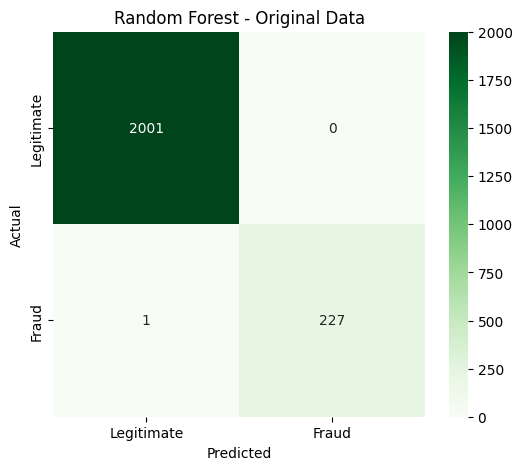

In [125]:
cm_rf = confusion_matrix(
    y_test,
    y_pred_rf
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Legitimate', 'Fraud'],
    yticklabels=['Legitimate', 'Fraud']
)

plt.title('Random Forest - Original Data')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

In [126]:
rf_weighted_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),

        ('classifier', RandomForestClassifier(
            n_estimators=300,
            class_weight='balanced',
            random_state=42,
            n_jobs=-1
        ))
    ]
)

rf_weighted_pipeline.fit(
    X_train,
    y_train
)

print("Class-weighted Random Forest trained successfully.")

Class-weighted Random Forest trained successfully.


In [127]:
y_pred_rf_weighted = rf_weighted_pipeline.predict(
    X_test
)

y_prob_rf_weighted = rf_weighted_pipeline.predict_proba(
    X_test
)[:, 1]


rfw_accuracy = accuracy_score(
    y_test, y_pred_rf_weighted
)

rfw_precision = precision_score(
    y_test, y_pred_rf_weighted
)

rfw_recall = recall_score(
    y_test, y_pred_rf_weighted
)

rfw_f1 = f1_score(
    y_test, y_pred_rf_weighted
)

rfw_roc_auc = roc_auc_score(
    y_test, y_prob_rf_weighted
)


print("Random Forest - Class Weighted")
print("-" * 45)

print(f"Accuracy : {rfw_accuracy:.4f}")
print(f"Precision: {rfw_precision:.4f}")
print(f"Recall   : {rfw_recall:.4f}")
print(f"F1 Score : {rfw_f1:.4f}")
print(f"ROC-AUC  : {rfw_roc_auc:.4f}")

Random Forest - Class Weighted
---------------------------------------------
Accuracy : 0.9996
Precision: 1.0000
Recall   : 0.9956
F1 Score : 0.9978
ROC-AUC  : 1.0000


In [128]:
model_results.append({
    'Model': 'Random Forest',
    'Sampling': 'Original',
    'Accuracy': rf_accuracy,
    'Precision': rf_precision,
    'Recall': rf_recall,
    'F1': rf_f1,
    'ROC_AUC': rf_roc_auc
})

model_results.append({
    'Model': 'Random Forest',
    'Sampling': 'Class Weight',
    'Accuracy': rfw_accuracy,
    'Precision': rfw_precision,
    'Recall': rfw_recall,
    'F1': rfw_f1,
    'ROC_AUC': rfw_roc_auc
})

pd.DataFrame(model_results).round(4)

,Model,Sampling,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,Original,0.99,1.00,0.95,0.97,0.99
1,Logistic Regression,Class Weight,0.99,0.94,0.98,0.96,0.99
2,Logistic Regression,SMOTE,0.99,0.94,0.98,0.96,0.99
3,Random Forest,Original,1.00,1.00,1.00,1.00,1.00
4,Random Forest,Class Weight,1.00,1.00,1.00,1.00,1.00


In [129]:
# ==========================================
# GRADIENT BOOSTING
# ==========================================

from sklearn.ensemble import GradientBoostingClassifier

gb_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),

        ('classifier', GradientBoostingClassifier(
            n_estimators=200,
            learning_rate=0.05,
            max_depth=3,
            random_state=42
        ))
    ]
)

gb_pipeline.fit(
    X_train,
    y_train
)

print("Gradient Boosting trained successfully.")

Gradient Boosting trained successfully.


In [132]:
y_pred_gb = gb_pipeline.predict(X_test)
y_prob_gb = gb_pipeline.predict_proba(X_test)[:, 1]

gb_accuracy = accuracy_score(
    y_test, y_pred_gb
)

gb_precision = precision_score(
    y_test, y_pred_gb
)

gb_recall = recall_score(
    y_test, y_pred_gb
)

gb_f1 = f1_score(
    y_test, y_pred_gb
)

gb_roc_auc = roc_auc_score(
    y_test, y_prob_gb
)

print("Gradient Boosting")
print("-" * 45)

print(f"Accuracy : {gb_accuracy:.4f}")
print(f"Precision: {gb_precision:.4f}")
print(f"Recall   : {gb_recall:.4f}")
print(f"F1 Score : {gb_f1:.4f}")
print(f"ROC-AUC  : {gb_roc_auc:.4f}")

Gradient Boosting
---------------------------------------------
Accuracy : 0.9996
Precision: 1.0000
Recall   : 0.9956
F1 Score : 0.9978
ROC-AUC  : 0.9973


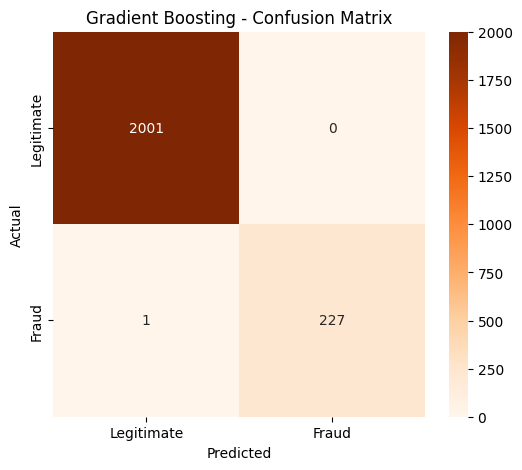

In [133]:
cm_gb = confusion_matrix(
    y_test,
    y_pred_gb
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_gb,
    annot=True,
    fmt='d',
    cmap='Oranges',
    xticklabels=['Legitimate', 'Fraud'],
    yticklabels=['Legitimate', 'Fraud']
)

plt.title('Gradient Boosting - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

In [134]:
model_results.append({
    'Model': 'Gradient Boosting',
    'Sampling': 'Original',
    'Accuracy': gb_accuracy,
    'Precision': gb_precision,
    'Recall': gb_recall,
    'F1': gb_f1,
    'ROC_AUC': gb_roc_auc
})

results_df = pd.DataFrame(model_results)

results_df.round(4)

,Model,Sampling,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,Original,0.99,1.00,0.95,0.97,0.99
1,Logistic Regression,Class Weight,0.99,0.94,0.98,0.96,0.99
2,Logistic Regression,SMOTE,0.99,0.94,0.98,0.96,0.99
3,Random Forest,Original,1.00,1.00,1.00,1.00,1.00
4,Random Forest,Class Weight,1.00,1.00,1.00,1.00,1.00
5,Gradient Boosting,Original,1.00,1.00,1.00,1.00,1.00


In [135]:
results_sorted = results_df.sort_values(
    by='F1',
    ascending=False
).reset_index(drop=True)

results_sorted.round(4)

,Model,Sampling,Accuracy,Precision,Recall,F1,ROC_AUC
0,Random Forest,Class Weight,1.00,1.00,1.00,1.00,1.00
1,Random Forest,Original,1.00,1.00,1.00,1.00,1.00
2,Gradient Boosting,Original,1.00,1.00,1.00,1.00,1.00
3,Logistic Regression,Original,0.99,1.00,0.95,0.97,0.99
4,Logistic Regression,Class Weight,0.99,0.94,0.98,0.96,0.99
5,Logistic Regression,SMOTE,0.99,0.94,0.98,0.96,0.99


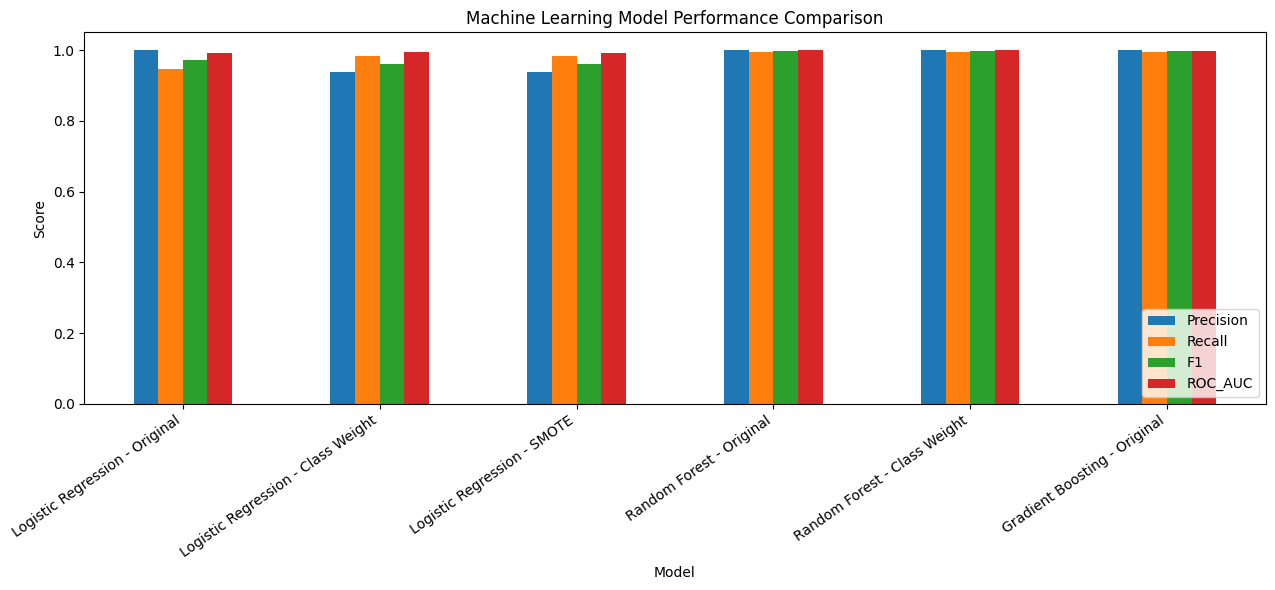

In [136]:
comparison_plot = results_df.copy()

comparison_plot['Model_Method'] = (
    comparison_plot['Model']
    + ' - '
    + comparison_plot['Sampling']
)

comparison_plot.set_index('Model_Method')[
    ['Precision', 'Recall', 'F1', 'ROC_AUC']
].plot(
    kind='bar',
    figsize=(13, 6)
)

plt.title('Machine Learning Model Performance Comparison')
plt.ylabel('Score')
plt.xlabel('Model')
plt.ylim(0, 1.05)
plt.xticks(rotation=35, ha='right')
plt.legend(loc='lower right')
plt.tight_layout()

plt.show()

In [137]:
results_df[
    ['Model', 'Sampling', 'Accuracy',
     'Precision', 'Recall', 'F1', 'ROC_AUC']
].round(6)

,Model,Sampling,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,Original,0.99,1.00,0.95,0.97,0.99
1,Logistic Regression,Class Weight,0.99,0.94,0.98,0.96,0.99
2,Logistic Regression,SMOTE,0.99,0.94,0.98,0.96,0.99
3,Random Forest,Original,1.00,1.00,1.00,1.00,1.00
4,Random Forest,Class Weight,1.00,1.00,1.00,1.00,1.00
5,Gradient Boosting,Original,1.00,1.00,1.00,1.00,1.00


In [138]:
print("Random Forest - Original")
print(confusion_matrix(y_test, y_pred_rf))

print("\nRandom Forest - Class Weight")
print(confusion_matrix(y_test, y_pred_rf_weighted))

print("\nGradient Boosting")
print(confusion_matrix(y_test, y_pred_gb))

Random Forest - Original
[[2001    0]
 [   1  227]]

Random Forest - Class Weight
[[2001    0]
 [   1  227]]

Gradient Boosting
[[2001    0]
 [   1  227]]


In [139]:
print("Is isFraud present in X?")
print('isFraud' in X.columns)

print("\nModel features:")
print(X.columns.tolist())

Is isFraud present in X?
False

Model features:
['step', 'type', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'hour_in_cycle', 'log_amount', 'origin_balance_change', 'origin_balance_error', 'destination_balance_change', 'destination_balance_error', 'is_merchant_dest', 'origin_new_balance_zero', 'destination_old_balance_zero', 'amount_to_oldbalance_ratio']


In [140]:
audit_features = [
    'amount',
    'origin_balance_change',
    'origin_balance_error',
    'destination_balance_change',
    'destination_balance_error',
    'amount_to_oldbalance_ratio'
]

model_df.groupby('isFraud')[
    audit_features
].agg(['mean', 'median', 'min', 'max'])

amount                                 origin_balance_change  \
                mean     median    min           max                  mean   
isFraud                                                                      
0         101,339.73  12,725.24   2.39  3,776,389.09            -24,808.18   
1       1,192,628.93 353,179.45 119.00 10,000,000.00          1,184,691.90   

                                               origin_balance_error            \
            median           min           max                 mean    median   
isFraud                                                                         
0           538.59 -1,030,100.15  2,317,408.88          -126,147.91 -5,573.72   
1       348,705.15          0.00 10,038,991.68            -7,937.03      0.00   

                                destination_balance_change           \
                  min       max                       mean   median   
isFraud                                                               
0       -3,776,389.09      0.01                 168,010.62     0.00   
1       -1,933,920.80 38,991.68                 625,074.35 3,733.04   

                                     destination_balance_error           \
                   min           max                      mean   median   
isFraud                                                                   
0       -13,100,000.00 18,299,820.00                -66,670.89 6,605.92   
1          -315,226.07 10,026,725.16                567,554.59 9,439.94   

                                     amount_to_oldbalance_ratio              \
                   min           max                       mean median  min   
isFraud                                                                       
0       -17,919,963.77 13,230,407.77                      14.05   0.06 0.00   
1        -8,875,516.29 10,000,000.00                       1.02   1.00 0.00   

                   
              max  
isFraud            
0       21,761.03  
1           29.53

In [141]:
# Get feature names after preprocessing

feature_names = rf_pipeline.named_steps[
    'preprocessor'
].get_feature_names_out()

importances = rf_pipeline.named_steps[
    'classifier'
].feature_importances_

feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(
    'Importance',
    ascending=False
).reset_index(drop=True)

feature_importance_df.head(15)

,Feature,Importance
0,num__step,0.31
1,num__hour_in_cycle,0.21
2,num__origin_balance_change,0.12
3,num__amount_to_oldbalance_ratio,0.10
4,num__origin_balance_error,0.08
5,num__log_amount,0.03
6,num__origin_new_balance_zero,0.03
7,num__amount,0.02
8,num__oldbalanceOrg,0.02
9,num__newbalanceOrig,0.02


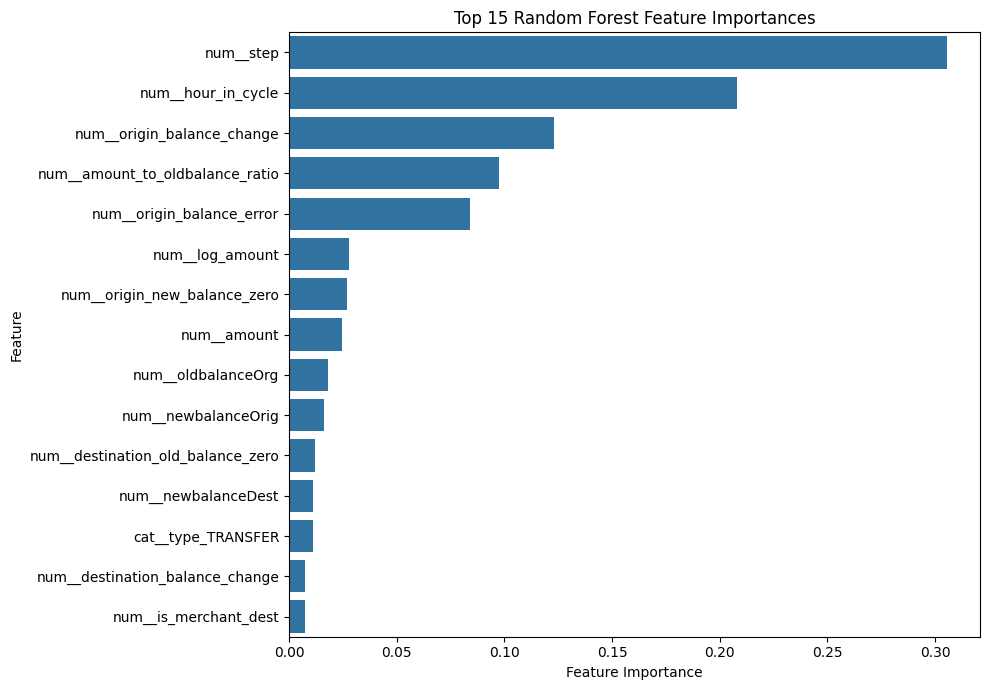

In [142]:
top_features = feature_importance_df.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x='Importance',
    y='Feature'
)

plt.title('Top 15 Random Forest Feature Importances')
plt.xlabel('Feature Importance')
plt.ylabel('Feature')

plt.tight_layout()
plt.show()

In [143]:
basic_features = [
    'step',
    'type',
    'amount',
    'oldbalanceOrg',
    'newbalanceOrig',
    'oldbalanceDest',
    'newbalanceDest'
]

X_basic = model_df[basic_features]

X_train_basic, X_test_basic, y_train_basic, y_test_basic = train_test_split(
    X_basic,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

basic_categorical = ['type']

basic_numerical = [
    'step',
    'amount',
    'oldbalanceOrg',
    'newbalanceOrig',
    'oldbalanceDest',
    'newbalanceDest'
]

basic_preprocessor = ColumnTransformer(
    transformers=[
        (
            'num',
            StandardScaler(),
            basic_numerical
        ),
        (
            'cat',
            OneHotEncoder(handle_unknown='ignore'),
            basic_categorical
        )
    ]
)

In [144]:
rf_basic_pipeline = Pipeline(
    steps=[
        ('preprocessor', basic_preprocessor),

        ('classifier', RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

rf_basic_pipeline.fit(
    X_train_basic,
    y_train_basic
)

y_pred_rf_basic = rf_basic_pipeline.predict(
    X_test_basic
)

y_prob_rf_basic = rf_basic_pipeline.predict_proba(
    X_test_basic
)[:, 1]

In [145]:
basic_results = {
    'Accuracy': accuracy_score(
        y_test_basic,
        y_pred_rf_basic
    ),

    'Precision': precision_score(
        y_test_basic,
        y_pred_rf_basic
    ),

    'Recall': recall_score(
        y_test_basic,
        y_pred_rf_basic
    ),

    'F1': f1_score(
        y_test_basic,
        y_pred_rf_basic
    ),

    'ROC_AUC': roc_auc_score(
        y_test_basic,
        y_prob_rf_basic
    )
}

comparison_ablation = pd.DataFrame({
    'Random Forest - Basic Features': basic_results,

    'Random Forest - Engineered Features': {
        'Accuracy': rf_accuracy,
        'Precision': rf_precision,
        'Recall': rf_recall,
        'F1': rf_f1,
        'ROC_AUC': rf_roc_auc
    }
}).T

comparison_ablation.round(6)

,Accuracy,Precision,Recall,F1,ROC_AUC
Random Forest - Basic Features,1.00,1.00,0.96,0.98,1.00
Random Forest - Engineered Features,1.00,1.00,1.00,1.00,1.00


In [146]:
# ==========================================
# ROBUSTNESS TEST: REMOVE TIME FEATURES
# ==========================================

features_without_time = [
    'type',
    'amount',
    'oldbalanceOrg',
    'newbalanceOrig',
    'oldbalanceDest',
    'newbalanceDest',
    'log_amount',
    'origin_balance_change',
    'origin_balance_error',
    'destination_balance_change',
    'destination_balance_error',
    'is_merchant_dest',
    'origin_new_balance_zero',
    'destination_old_balance_zero',
    'amount_to_oldbalance_ratio'
]

X_no_time = model_df[features_without_time]

categorical_no_time = ['type']

numerical_no_time = [
    col for col in features_without_time
    if col not in categorical_no_time
]

X_train_nt, X_test_nt, y_train_nt, y_test_nt = train_test_split(
    X_no_time,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

preprocessor_no_time = ColumnTransformer(
    transformers=[
        (
            'num',
            StandardScaler(),
            numerical_no_time
        ),
        (
            'cat',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_no_time
        )
    ]
)

rf_no_time_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor_no_time),
        (
            'classifier',
            RandomForestClassifier(
                n_estimators=300,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

rf_no_time_pipeline.fit(
    X_train_nt,
    y_train_nt
)

y_pred_rf_nt = rf_no_time_pipeline.predict(
    X_test_nt
)

y_prob_rf_nt = rf_no_time_pipeline.predict_proba(
    X_test_nt
)[:, 1]

In [153]:
no_time_results = {
    'Accuracy': accuracy_score(
        y_test_nt, y_pred_rf_nt
    ),
    'Precision': precision_score(
        y_test_nt, y_pred_rf_nt
    ),
    'Recall': recall_score(
        y_test_nt, y_pred_rf_nt
    ),
    'F1': f1_score(
        y_test_nt, y_pred_rf_nt
    ),
    'ROC_AUC': roc_auc_score(
        y_test_nt, y_prob_rf_nt
    )
}

time_robustness_comparison = pd.DataFrame({
    'Random Forest - With Time': {
        'Accuracy': rf_accuracy,
        'Precision': rf_precision,
        'Recall': rf_recall,
        'F1': rf_f1,
        'ROC_AUC': rf_roc_auc
    },

    'Random Forest - Without Time': no_time_results

}).T

time_robustness_comparison.round(6)

,Accuracy,Precision,Recall,F1,ROC_AUC
Random Forest - With Time,1.00,1.00,1.00,1.00,1.00
Random Forest - Without Time,1.00,1.00,0.98,0.99,0.99


In [147]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc'
}

print("5-Fold Stratified Cross-Validation configured.")

5-Fold Stratified Cross-Validation configured.


In [148]:
rf_cv_scores = cross_validate(
    rf_pipeline,
    X,
    y,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

rf_cv_results = pd.DataFrame({
    'Fold': range(1, 6),
    'Accuracy': rf_cv_scores['test_accuracy'],
    'Precision': rf_cv_scores['test_precision'],
    'Recall': rf_cv_scores['test_recall'],
    'F1': rf_cv_scores['test_f1'],
    'ROC_AUC': rf_cv_scores['test_roc_auc']
})

rf_cv_results.round(4)

,Fold,Accuracy,Precision,Recall,F1,ROC_AUC
0,1,1.00,1.00,1.00,1.00,1.00
1,2,1.00,1.00,1.00,1.00,1.00
2,3,1.00,1.00,1.00,1.00,1.00
3,4,1.00,1.00,1.00,1.00,1.00
4,5,1.00,1.00,1.00,1.00,1.00


In [149]:
rf_cv_summary = pd.DataFrame({
    'Mean': rf_cv_results[
        ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC_AUC']
    ].mean(),

    'Std_Dev': rf_cv_results[
        ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC_AUC']
    ].std(),

    'Minimum': rf_cv_results[
        ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC_AUC']
    ].min(),

    'Maximum': rf_cv_results[
        ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC_AUC']
    ].max()
})

rf_cv_summary.round(4)

,Mean,Std_Dev,Minimum,Maximum
Accuracy,1.00,0.00,1.00,1.00
Precision,1.00,0.00,1.00,1.00
Recall,1.00,0.00,1.00,1.00
F1,1.00,0.00,1.00,1.00
ROC_AUC,1.00,0.00,1.00,1.00


In [150]:
gb_cv_scores = cross_validate(
    gb_pipeline,
    X,
    y,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

gb_cv_results = pd.DataFrame({
    'Fold': range(1, 6),
    'Accuracy': gb_cv_scores['test_accuracy'],
    'Precision': gb_cv_scores['test_precision'],
    'Recall': gb_cv_scores['test_recall'],
    'F1': gb_cv_scores['test_f1'],
    'ROC_AUC': gb_cv_scores['test_roc_auc']
})

gb_cv_results.round(4)

,Fold,Accuracy,Precision,Recall,F1,ROC_AUC
0,1,1.00,1.00,1.00,1.00,1.00
1,2,1.00,1.00,1.00,1.00,1.00
2,3,1.00,1.00,1.00,1.00,1.00
3,4,1.00,1.00,1.00,1.00,1.00
4,5,1.00,1.00,1.00,1.00,1.00


In [151]:
gb_cv_summary = pd.DataFrame({
    'Mean': gb_cv_results[
        ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC_AUC']
    ].mean(),

    'Std_Dev': gb_cv_results[
        ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC_AUC']
    ].std(),

    'Minimum': gb_cv_results[
        ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC_AUC']
    ].min(),

    'Maximum': gb_cv_results[
        ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC_AUC']
    ].max()
})

gb_cv_summary.round(4)

,Mean,Std_Dev,Minimum,Maximum
Accuracy,1.00,0.00,1.00,1.00
Precision,1.00,0.00,1.00,1.00
Recall,1.00,0.00,1.00,1.00
F1,1.00,0.00,1.00,1.00
ROC_AUC,1.00,0.00,1.00,1.00


In [152]:
cv_model_comparison = pd.DataFrame({
    'Random Forest': {
        'Accuracy': rf_cv_scores['test_accuracy'].mean(),
        'Precision': rf_cv_scores['test_precision'].mean(),
        'Recall': rf_cv_scores['test_recall'].mean(),
        'F1': rf_cv_scores['test_f1'].mean(),
        'ROC_AUC': rf_cv_scores['test_roc_auc'].mean()
    },

    'Gradient Boosting': {
        'Accuracy': gb_cv_scores['test_accuracy'].mean(),
        'Precision': gb_cv_scores['test_precision'].mean(),
        'Recall': gb_cv_scores['test_recall'].mean(),
        'F1': gb_cv_scores['test_f1'].mean(),
        'ROC_AUC': gb_cv_scores['test_roc_auc'].mean()
    }
}).T

cv_model_comparison.round(4)

,Accuracy,Precision,Recall,F1,ROC_AUC
Random Forest,1.00,1.00,1.00,1.00,1.00
Gradient Boosting,1.00,1.00,1.00,1.00,1.00


Final Model Selection

Based on the holdout test results and stratified cross-validation results, Random Forest and Gradient Boosting demonstrated the strongest predictive performance.

Random Forest with engineered features was selected as the candidate final model because:

- It achieved excellent performance across Accuracy, Precision, Recall, F1-Score and ROC-AUC.
- Performance remained stable during stratified cross-validation.
- The model provides feature-importance information that supports interpretation of fraud patterns.
- Class weighting did not demonstrate a meaningful improvement over the original Random Forest model.
- SMOTE was therefore not considered necessary for the final model.
- A robustness experiment showed that the model continued to perform strongly even after removing the simulation-time features.

Because the dataset is simulated and exhibits highly separable fraud patterns, the near-perfect model performance should not be assumed to represent expected performance on real-world banking transaction data.

In [154]:
# ==========================================
# FINANCIAL IMPACT ANALYSIS
# ==========================================

financial_test = X_test.copy()

financial_test['Actual_Fraud'] = y_test.values
financial_test['Predicted_Fraud'] = y_pred_rf
financial_test['Fraud_Probability'] = y_prob_rf

financial_test.head()

,step,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,hour_in_cycle,log_amount,origin_balance_change,origin_balance_error,destination_balance_change,destination_balance_error,is_merchant_dest,origin_new_balance_zero,destination_old_balance_zero,amount_to_oldbalance_ratio,Actual_Fraud,Predicted_Fraud,Fraud_Probability
4522,2,PAYMENT,"23,147.49","169,352.26","146,204.77",0.00,0.00,2,10.05,"23,147.49",0.00,0.00,"23,147.49",1,0,1,0.14,0,0,0.00
7816,6,PAYMENT,"17,978.87","31,239.00","13,260.13",0.00,0.00,6,9.80,"17,978.87",0.00,0.00,"17,978.87",1,0,1,0.58,0,0,0.00
1494,1,TRANSFER,"100,677.86",0.00,0.00,"701,567.56","55,974.56",1,11.52,0.00,"-100,677.86","-645,593.00","746,270.86",0,1,0,0.00,0,0,0.00
1713,1,PAYMENT,"2,056.59",0.00,0.00,0.00,0.00,1,7.63,0.00,"-2,056.59",0.00,"2,056.59",1,1,1,0.00,0,0,0.00
1506,1,TRANSFER,"161,217.61",0.00,0.00,"199,733.00","5,602,234.95",1,11.99,0.00,"-161,217.61","5,402,501.95","-5,241,284.34",0,1,0,0.00,0,0,0.00


In [155]:
conditions = [
    (financial_test['Actual_Fraud'] == 1) &
    (financial_test['Predicted_Fraud'] == 1),

    (financial_test['Actual_Fraud'] == 0) &
    (financial_test['Predicted_Fraud'] == 1),

    (financial_test['Actual_Fraud'] == 1) &
    (financial_test['Predicted_Fraud'] == 0),

    (financial_test['Actual_Fraud'] == 0) &
    (financial_test['Predicted_Fraud'] == 0)
]

choices = [
    'True Positive',
    'False Positive',
    'False Negative',
    'True Negative'
]

financial_test['Classification'] = np.select(
    conditions,
    choices,
    default='Unknown'
)

financial_test['Classification'].value_counts()

,count
Classification,
True Negative,2001
True Positive,227
False Negative,1


In [156]:
financial_impact = financial_test.groupby(
    'Classification'
).agg(
    Transaction_Count=('amount', 'count'),
    Total_Amount=('amount', 'sum'),
    Average_Amount=('amount', 'mean')
).sort_values(
    'Total_Amount',
    ascending=False
)

financial_impact

,Transaction_Count,Total_Amount,Average_Amount
Classification,,,
True Positive,227,"235,430,525.04","1,037,138.88"
True Negative,2001,"205,491,066.96","102,694.19"
False Negative,1,"416,001.33","416,001.33"


In [157]:
actual_fraud_amount = financial_test.loc[
    financial_test['Actual_Fraud'] == 1,
    'amount'
].sum()

detected_fraud_amount = financial_test.loc[
    financial_test['Classification'] == 'True Positive',
    'amount'
].sum()

missed_fraud_amount = financial_test.loc[
    financial_test['Classification'] == 'False Negative',
    'amount'
].sum()

false_positive_amount = financial_test.loc[
    financial_test['Classification'] == 'False Positive',
    'amount'
].sum()


print("FINANCIAL FRAUD ANALYSIS")
print("=" * 50)

print(
    f"Actual Fraud Transaction Value : "
    f"{actual_fraud_amount:,.2f}"
)

print(
    f"Detected Fraud Value           : "
    f"{detected_fraud_amount:,.2f}"
)

print(
    f"Missed Fraud Exposure          : "
    f"{missed_fraud_amount:,.2f}"
)

print(
    f"Legitimate Value Flagged       : "
    f"{false_positive_amount:,.2f}"
)

FINANCIAL FRAUD ANALYSIS
Actual Fraud Transaction Value : 235,846,526.37
Detected Fraud Value           : 235,430,525.04
Missed Fraud Exposure          : 416,001.33
Legitimate Value Flagged       : 0.00


In [158]:
if actual_fraud_amount > 0:

    fraud_value_detection_rate = (
        detected_fraud_amount
        / actual_fraud_amount
    ) * 100

else:
    fraud_value_detection_rate = 0


print(
    f"Fraud Value Detection Rate: "
    f"{fraud_value_detection_rate:.2f}%"
)

Fraud Value Detection Rate: 99.82%


In [159]:
tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_pred_rf
).ravel()


business_metrics = pd.DataFrame({
    'Metric': [
        'True Positives',
        'False Positives',
        'False Negatives',
        'True Negatives',
        'Fraud Detection Rate',
        'Fraud Value Detection Rate'
    ],

    'Value': [
        tp,
        fp,
        fn,
        tn,
        f"{rf_recall * 100:.2f}%",
        f"{fraud_value_detection_rate:.2f}%"
    ]
})

business_metrics

,Metric,Value
0,True Positives,227
1,False Positives,0
2,False Negatives,1
3,True Negatives,2001
4,Fraud Detection Rate,99.56%
5,Fraud Value Detection Rate,99.82%


# ==========================================
# SCENARIO-BASED FINANCIAL IMPACT
# ==========================================

# Illustrative assumptions only.
# These values are NOT provided by the dataset.

recovery_rate = 0.80
investigation_cost_per_alert = 50

Financial Scenario Assumptions

The dataset does not provide operational information such as fraud recovery rates or investigation costs.

Therefore, the following values are used only for scenario analysis and should not be interpreted as actual bank costs:

- Assumed fraud recovery/prevention rate: 80%
- Assumed investigation cost per flagged transaction: 50 local currency units

The scenario parameters can be modified to evaluate different business conditions.

In [161]:
recovery_rate = 0.80
investigation_cost_per_alert = 50

estimated_prevented_loss = (
    detected_fraud_amount
    * recovery_rate
)

investigation_cost = (
    (tp + fp)
    * investigation_cost_per_alert
)

remaining_fraud_loss = (
    actual_fraud_amount
    - estimated_prevented_loss
)

estimated_net_benefit = (
    estimated_prevented_loss
    - investigation_cost
)


print("SCENARIO-BASED FINANCIAL IMPACT")
print("=" * 50)

print(
    f"Estimated Prevented Fraud Loss : "
    f"{estimated_prevented_loss:,.2f}"
)

print(
    f"Estimated Investigation Cost   : "
    f"{investigation_cost:,.2f}"
)

print(
    f"Remaining Fraud Loss            : "
    f"{remaining_fraud_loss:,.2f}"
)

print(
    f"Estimated Net Benefit           : "
    f"{estimated_net_benefit:,.2f}"
)

SCENARIO-BASED FINANCIAL IMPACT
Estimated Prevented Fraud Loss : 188,344,420.03
Estimated Investigation Cost   : 11,350.00
Remaining Fraud Loss            : 47,502,106.34
Estimated Net Benefit           : 188,333,070.03


In [162]:
financial_summary = pd.DataFrame({
    'Metric': [
        'Actual Fraud Value',
        'Detected Fraud Value',
        'Missed Fraud Exposure',
        'Fraud Value Detection Rate',
        'Estimated Prevented Loss',
        'Estimated Investigation Cost',
        'Estimated Net Benefit'
    ],

    'Value': [
        actual_fraud_amount,
        detected_fraud_amount,
        missed_fraud_amount,
        fraud_value_detection_rate,
        estimated_prevented_loss,
        investigation_cost,
        estimated_net_benefit
    ]
})

financial_summary

,Metric,Value
0,Actual Fraud Value,"235,846,526.37"
1,Detected Fraud Value,"235,430,525.04"
2,Missed Fraud Exposure,"416,001.33"
3,Fraud Value Detection Rate,99.82
4,Estimated Prevented Loss,"188,344,420.03"
5,Estimated Investigation Cost,"11,350.00"
6,Estimated Net Benefit,"188,333,070.03"


In [163]:
missed_fraud = financial_test[
    financial_test['Classification'] == 'False Negative'
][[
    'type',
    'amount',
    'Fraud_Probability',
    'oldbalanceOrg',
    'newbalanceOrig',
    'oldbalanceDest',
    'newbalanceDest'
]]

missed_fraud

,type,amount,Fraud_Probability,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest
6,CASH_OUT,"416,001.33",0.03,0.00,0.00,102.00,"9,291,619.62"


In [164]:
# ==========================================
# CLASSIFICATION THRESHOLD ANALYSIS
# ==========================================

thresholds = np.arange(
    0.10,
    0.91,
    0.05
)

threshold_results = []

for threshold in thresholds:

    y_pred_threshold = (
        y_prob_rf >= threshold
    ).astype(int)

    tn_t, fp_t, fn_t, tp_t = confusion_matrix(
        y_test,
        y_pred_threshold
    ).ravel()

    threshold_results.append({

        'Threshold': threshold,

        'Accuracy': accuracy_score(
            y_test,
            y_pred_threshold
        ),

        'Precision': precision_score(
            y_test,
            y_pred_threshold,
            zero_division=0
        ),

        'Recall': recall_score(
            y_test,
            y_pred_threshold
        ),

        'F1': f1_score(
            y_test,
            y_pred_threshold
        ),

        'False_Positives': fp_t,

        'False_Negatives': fn_t,

        'True_Positives': tp_t,

        'True_Negatives': tn_t
    })


threshold_df = pd.DataFrame(
    threshold_results
)

threshold_df.round(4)

,Threshold,Accuracy,Precision,Recall,F1,False_Positives,False_Negatives,True_Positives,True_Negatives
0,0.10,1.00,1.00,1.00,1.00,1,1,227,2000
1,0.15,1.00,1.00,1.00,1.00,0,1,227,2001
2,0.20,1.00,1.00,1.00,1.00,0,1,227,2001
3,0.25,1.00,1.00,1.00,1.00,0,1,227,2001
4,0.30,1.00,1.00,1.00,1.00,0,1,227,2001
5,0.35,1.00,1.00,1.00,1.00,0,1,227,2001
6,0.40,1.00,1.00,1.00,1.00,0,1,227,2001
7,0.45,1.00,1.00,1.00,1.00,0,1,227,2001
8,0.50,1.00,1.00,1.00,1.00,0,1,227,2001
9,0.55,1.00,1.00,1.00,1.00,0,1,227,2001


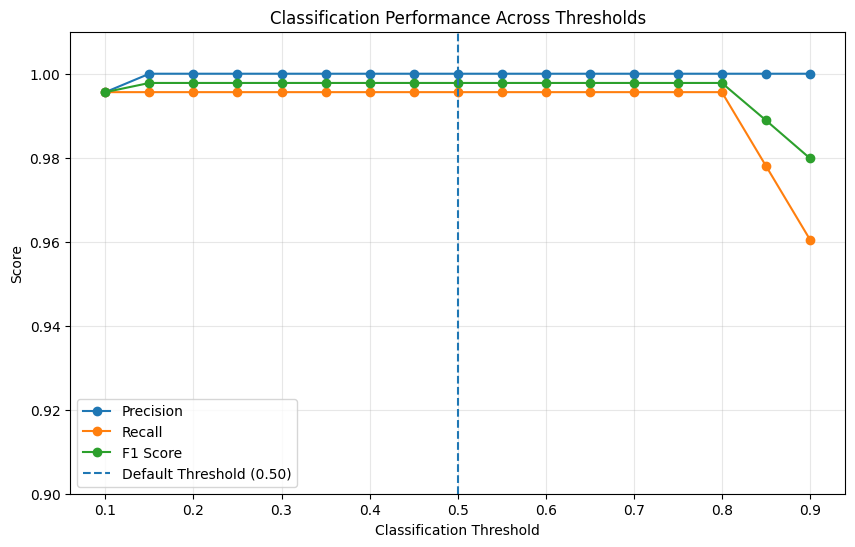

In [165]:
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df['Threshold'],
    threshold_df['Precision'],
    marker='o',
    label='Precision'
)

plt.plot(
    threshold_df['Threshold'],
    threshold_df['Recall'],
    marker='o',
    label='Recall'
)

plt.plot(
    threshold_df['Threshold'],
    threshold_df['F1'],
    marker='o',
    label='F1 Score'
)

plt.axvline(
    x=0.50,
    linestyle='--',
    label='Default Threshold (0.50)'
)

plt.title(
    'Classification Performance Across Thresholds'
)

plt.xlabel('Classification Threshold')
plt.ylabel('Score')

plt.ylim(0.90, 1.01)

plt.legend()
plt.grid(alpha=0.3)

plt.show()

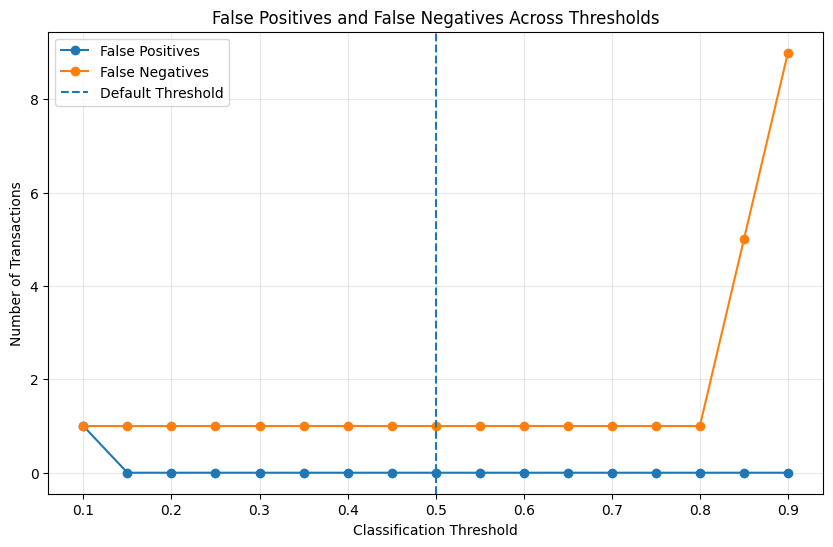

In [166]:
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df['Threshold'],
    threshold_df['False_Positives'],
    marker='o',
    label='False Positives'
)

plt.plot(
    threshold_df['Threshold'],
    threshold_df['False_Negatives'],
    marker='o',
    label='False Negatives'
)

plt.axvline(
    x=0.50,
    linestyle='--',
    label='Default Threshold'
)

plt.title(
    'False Positives and False Negatives Across Thresholds'
)

plt.xlabel('Classification Threshold')
plt.ylabel('Number of Transactions')

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [167]:
financial_threshold_results = []

amount_test = X_test['amount'].values

for threshold in thresholds:

    predictions = (
        y_prob_rf >= threshold
    ).astype(int)

    actual = y_test.values

    tp_mask = (
        (actual == 1) &
        (predictions == 1)
    )

    fn_mask = (
        (actual == 1) &
        (predictions == 0)
    )

    fp_mask = (
        (actual == 0) &
        (predictions == 1)
    )

    detected_value = amount_test[
        tp_mask
    ].sum()

    missed_value = amount_test[
        fn_mask
    ].sum()

    legitimate_flagged_value = amount_test[
        fp_mask
    ].sum()

    financial_threshold_results.append({

        'Threshold': threshold,

        'Detected_Fraud_Value':
            detected_value,

        'Missed_Fraud_Exposure':
            missed_value,

        'Legitimate_Value_Flagged':
            legitimate_flagged_value
    })


financial_threshold_df = pd.DataFrame(
    financial_threshold_results
)

financial_threshold_df.round(2)

,Threshold,Detected_Fraud_Value,Missed_Fraud_Exposure,Legitimate_Value_Flagged
0,0.10,"235,430,525.04","416,001.33","2,241,254.39"
1,0.15,"235,430,525.04","416,001.33",0.00
2,0.20,"235,430,525.04","416,001.33",0.00
3,0.25,"235,430,525.04","416,001.33",0.00
4,0.30,"235,430,525.04","416,001.33",0.00
5,0.35,"235,430,525.04","416,001.33",0.00
6,0.40,"235,430,525.04","416,001.33",0.00
7,0.45,"235,430,525.04","416,001.33",0.00
8,0.50,"235,430,525.04","416,001.33",0.00
9,0.55,"235,430,525.04","416,001.33",0.00


In [168]:
threshold_analysis = pd.merge(
    threshold_df,
    financial_threshold_df,
    on='Threshold'
)

threshold_analysis[
    [
        'Threshold',
        'Precision',
        'Recall',
        'F1',
        'False_Positives',
        'False_Negatives',
        'Detected_Fraud_Value',
        'Missed_Fraud_Exposure'
    ]
].round(4)

,Threshold,Precision,Recall,F1,False_Positives,False_Negatives,Detected_Fraud_Value,Missed_Fraud_Exposure
0,0.10,1.00,1.00,1.00,1,1,"235,430,525.04","416,001.33"
1,0.15,1.00,1.00,1.00,0,1,"235,430,525.04","416,001.33"
2,0.20,1.00,1.00,1.00,0,1,"235,430,525.04","416,001.33"
3,0.25,1.00,1.00,1.00,0,1,"235,430,525.04","416,001.33"
4,0.30,1.00,1.00,1.00,0,1,"235,430,525.04","416,001.33"
5,0.35,1.00,1.00,1.00,0,1,"235,430,525.04","416,001.33"
6,0.40,1.00,1.00,1.00,0,1,"235,430,525.04","416,001.33"
7,0.45,1.00,1.00,1.00,0,1,"235,430,525.04","416,001.33"
8,0.50,1.00,1.00,1.00,0,1,"235,430,525.04","416,001.33"
9,0.55,1.00,1.00,1.00,0,1,"235,430,525.04","416,001.33"


In [169]:
zero_missed_fraud = threshold_analysis[
    threshold_analysis[
        'False_Negatives'
    ] == 0
][[
    'Threshold',
    'Precision',
    'Recall',
    'F1',
    'False_Positives',
    'False_Negatives',
    'Detected_Fraud_Value',
    'Missed_Fraud_Exposure'
]]

zero_missed_fraud.round(4)

,Threshold,Precision,Recall,F1,False_Positives,False_Negatives,Detected_Fraud_Value,Missed_Fraud_Exposure


In [170]:
fine_thresholds = [
    0.01, 0.02, 0.025, 0.03, 0.035,
    0.04, 0.05, 0.075, 0.10,
    0.20, 0.30, 0.40, 0.50
]

fine_results = []

amount_test = X_test['amount'].values
actual = y_test.values

for threshold in fine_thresholds:

    predictions = (y_prob_rf >= threshold).astype(int)

    tn_t, fp_t, fn_t, tp_t = confusion_matrix(
        actual,
        predictions
    ).ravel()

    detected_value = amount_test[
        (actual == 1) & (predictions == 1)
    ].sum()

    missed_value = amount_test[
        (actual == 1) & (predictions == 0)
    ].sum()

    legitimate_flagged_value = amount_test[
        (actual == 0) & (predictions == 1)
    ].sum()

    fine_results.append({
        'Threshold': threshold,
        'Precision': precision_score(
            actual, predictions, zero_division=0
        ),
        'Recall': recall_score(
            actual, predictions
        ),
        'F1': f1_score(
            actual, predictions
        ),
        'TP': tp_t,
        'FP': fp_t,
        'FN': fn_t,
        'TN': tn_t,
        'Detected_Fraud_Value': detected_value,
        'Missed_Fraud_Exposure': missed_value,
        'Legitimate_Value_Flagged':
            legitimate_flagged_value
    })

fine_threshold_df = pd.DataFrame(fine_results)

fine_threshold_df.round(4)

,Threshold,Precision,Recall,F1,TP,FP,FN,TN,Detected_Fraud_Value,Missed_Fraud_Exposure,Legitimate_Value_Flagged
0,0.01,0.84,1.00,0.91,228,45,0,1956,"235,846,526.37",0.00,"13,428,514.23"
1,0.02,0.91,1.00,0.95,228,23,0,1978,"235,846,526.37",0.00,"8,023,526.05"
2,0.03,0.93,1.00,0.96,228,18,0,1983,"235,846,526.37",0.00,"6,944,313.66"
3,0.03,0.94,1.00,0.97,227,15,1,1986,"235,430,525.04","416,001.33","4,845,735.04"
4,0.04,0.95,1.00,0.97,227,12,1,1989,"235,430,525.04","416,001.33","3,852,053.73"
5,0.04,0.95,1.00,0.97,227,11,1,1990,"235,430,525.04","416,001.33","3,851,891.56"
6,0.05,0.97,1.00,0.98,227,7,1,1994,"235,430,525.04","416,001.33","3,268,102.65"
7,0.07,0.99,1.00,0.99,227,2,1,1999,"235,430,525.04","416,001.33","2,339,501.66"
8,0.10,1.00,1.00,1.00,227,1,1,2000,"235,430,525.04","416,001.33","2,241,254.39"
9,0.20,1.00,1.00,1.00,227,0,1,2001,"235,430,525.04","416,001.33",0.00


In [171]:
fine_thresholds = [
    0.01, 0.02, 0.025, 0.03, 0.035,
    0.04, 0.05, 0.075, 0.10,
    0.20, 0.30, 0.40, 0.50
]

fine_results = []

amount_test = X_test['amount'].values
actual = y_test.values

for threshold in fine_thresholds:

    predictions = (y_prob_rf >= threshold).astype(int)

    tn_t, fp_t, fn_t, tp_t = confusion_matrix(
        actual,
        predictions
    ).ravel()

    detected_value = amount_test[
        (actual == 1) & (predictions == 1)
    ].sum()

    missed_value = amount_test[
        (actual == 1) & (predictions == 0)
    ].sum()

    legitimate_flagged_value = amount_test[
        (actual == 0) & (predictions == 1)
    ].sum()

    fine_results.append({
        'Threshold': threshold,
        'Precision': precision_score(
            actual, predictions, zero_division=0
        ),
        'Recall': recall_score(
            actual, predictions
        ),
        'F1': f1_score(
            actual, predictions
        ),
        'TP': tp_t,
        'FP': fp_t,
        'FN': fn_t,
        'TN': tn_t,
        'Detected_Fraud_Value': detected_value,
        'Missed_Fraud_Exposure': missed_value,
        'Legitimate_Value_Flagged':
            legitimate_flagged_value
    })

fine_threshold_df = pd.DataFrame(fine_results)

fine_threshold_df.round(4)

,Threshold,Precision,Recall,F1,TP,FP,FN,TN,Detected_Fraud_Value,Missed_Fraud_Exposure,Legitimate_Value_Flagged
0,0.01,0.84,1.00,0.91,228,45,0,1956,"235,846,526.37",0.00,"13,428,514.23"
1,0.02,0.91,1.00,0.95,228,23,0,1978,"235,846,526.37",0.00,"8,023,526.05"
2,0.03,0.93,1.00,0.96,228,18,0,1983,"235,846,526.37",0.00,"6,944,313.66"
3,0.03,0.94,1.00,0.97,227,15,1,1986,"235,430,525.04","416,001.33","4,845,735.04"
4,0.04,0.95,1.00,0.97,227,12,1,1989,"235,430,525.04","416,001.33","3,852,053.73"
5,0.04,0.95,1.00,0.97,227,11,1,1990,"235,430,525.04","416,001.33","3,851,891.56"
6,0.05,0.97,1.00,0.98,227,7,1,1994,"235,430,525.04","416,001.33","3,268,102.65"
7,0.07,0.99,1.00,0.99,227,2,1,1999,"235,430,525.04","416,001.33","2,339,501.66"
8,0.10,1.00,1.00,1.00,227,1,1,2000,"235,430,525.04","416,001.33","2,241,254.39"
9,0.20,1.00,1.00,1.00,227,0,1,2001,"235,430,525.04","416,001.33",0.00


In [172]:
missed_exact = financial_test.loc[
    financial_test['Classification'] == 'False Negative',
    ['type', 'amount', 'Fraud_Probability']
].copy()

pd.set_option('display.precision', 10)

missed_exact

,type,amount,Fraud_Probability
6,CASH_OUT,"416,001.33",0.03


Final Model and Threshold Decision

Random Forest with engineered features was selected as the final fraud detection model.

The default classification threshold of **0.50** was retained after performing threshold sensitivity analysis.

At the 0.50 threshold, the model:

- Correctly detected 227 out of 228 fraudulent transactions.
- Achieved approximately 99.56% fraud recall.
- Achieved 100% precision on the holdout test set.
- Produced zero false-positive alerts.
- Detected approximately 99.82% of the total fraudulent transaction value.
- Missed one fraudulent transaction with a value of 416,001.33 local currency units.

The missed transaction received a very low fraud probability of approximately 0.03. Capturing this transaction would require reducing the classification threshold substantially.

The threshold analysis showed that lowering the threshold sufficiently to detect all fraud cases introduced additional false-positive alerts and caused legitimate transaction value to be flagged.

Therefore, the 0.50 threshold was retained as a balanced operating point between fraud detection and false-positive risk.

This threshold should not be interpreted as universally optimal. In a real financial institution, the operating threshold should be determined using institution-specific fraud losses, investigation costs, customer-friction costs, risk appetite and operational capacity.

In [173]:
# ==========================================
# FINAL MODEL EVALUATION
# ==========================================

FINAL_THRESHOLD = 0.50

final_model = rf_pipeline

final_probabilities = final_model.predict_proba(
    X_test
)[:, 1]

final_predictions = (
    final_probabilities >= FINAL_THRESHOLD
).astype(int)

print("Final model: Random Forest")
print("Final threshold:", FINAL_THRESHOLD)

Final model: Random Forest
Final threshold: 0.5


In [174]:
from sklearn.metrics import average_precision_score

final_accuracy = accuracy_score(
    y_test, final_predictions
)

final_precision = precision_score(
    y_test, final_predictions
)

final_recall = recall_score(
    y_test, final_predictions
)

final_f1 = f1_score(
    y_test, final_predictions
)

final_roc_auc = roc_auc_score(
    y_test, final_probabilities
)

final_pr_auc = average_precision_score(
    y_test, final_probabilities
)

print("FINAL MODEL PERFORMANCE")
print("=" * 45)

print(f"Accuracy  : {final_accuracy:.6f}")
print(f"Precision : {final_precision:.6f}")
print(f"Recall    : {final_recall:.6f}")
print(f"F1 Score  : {final_f1:.6f}")
print(f"ROC-AUC   : {final_roc_auc:.6f}")
print(f"PR-AUC    : {final_pr_auc:.6f}")

FINAL MODEL PERFORMANCE
Accuracy  : 0.999551
Precision : 1.000000
Recall    : 0.995614
F1 Score  : 0.997802
ROC-AUC   : 0.999964
PR-AUC    : 0.999679


True Negatives : 2001
False Positives: 0
False Negatives: 1
True Positives : 227


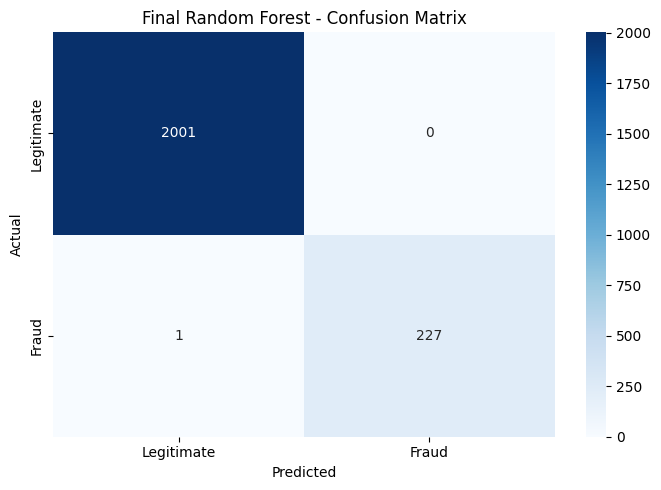

In [175]:
final_cm = confusion_matrix(
    y_test,
    final_predictions
)

tn_final, fp_final, fn_final, tp_final = (
    final_cm.ravel()
)

print("True Negatives :", tn_final)
print("False Positives:", fp_final)
print("False Negatives:", fn_final)
print("True Positives :", tp_final)

plt.figure(figsize=(7, 5))

sns.heatmap(
    final_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Legitimate', 'Fraud'],
    yticklabels=['Legitimate', 'Fraud']
)

plt.title(
    'Final Random Forest - Confusion Matrix'
)

plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.tight_layout()
plt.show()

In [176]:
# ==========================================
# SAVE FINAL MODEL
# ==========================================

import joblib

joblib.dump(
    final_model,
    'fraud_detection_pipeline.pkl'
)

print(
    "Final model saved as: "
    "fraud_detection_pipeline.pkl"
)

Final model saved as: fraud_detection_pipeline.pkl


In [177]:
model_config = {
    'threshold': FINAL_THRESHOLD,
    'model_name': 'Random Forest',
    'feature_columns': features
}

joblib.dump(
    model_config,
    'model_config.pkl'
)

print(
    "Model configuration saved as: "
    "model_config.pkl"
)

Model configuration saved as: model_config.pkl


In [178]:
loaded_model = joblib.load(
    'fraud_detection_pipeline.pkl'
)

loaded_config = joblib.load(
    'model_config.pkl'
)

test_probabilities = loaded_model.predict_proba(
    X_test.head(5)
)[:, 1]

print("Loaded threshold:")
print(loaded_config['threshold'])

print("\nTest probabilities:")
print(test_probabilities)

Loaded threshold:
0.5

Test probabilities:
[0. 0. 0. 0. 0.]


In [185]:
fraud_examples = X_test[y_test == 1].head(5)

fraud_probabilities = loaded_model.predict_proba(
    fraud_examples
)[:, 1]

print("Fraud example probabilities:")
print(fraud_probabilities)

Fraud example probabilities:
[1. 1. 1. 1. 1.]


In [179]:
results_df.to_csv(
    'model_comparison.csv',
    index=False
)

print("Model comparison exported.")

Model comparison exported.


In [180]:
fine_threshold_df.to_csv(
    'threshold_analysis.csv',
    index=False
)

print("Threshold analysis exported.")

Threshold analysis exported.


In [181]:
feature_importance_df.to_csv(
    'feature_importance.csv',
    index=False
)

print("Feature importance exported.")

Feature importance exported.


In [182]:
financial_summary.to_csv(
    'financial_summary.csv',
    index=False
)

print("Financial summary exported.")

Financial summary exported.


In [183]:
from google.colab import files

files.download(
    'fraud_detection_pipeline.pkl'
)

files.download(
    'model_config.pkl'
)

files.download(
    'model_comparison.csv'
)

files.download(
    'threshold_analysis.csv'
)

files.download(
    'feature_importance.csv'
)

files.download(
    'financial_summary.csv'
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Streamlit Application Development

The final Random Forest pipeline is deployed through an interactive
Streamlit application for fraud prediction, model analytics, and
financial risk analysis.

In [186]:
%%writefile app.py

# Streamlit code will go here

Writing app.py


In [187]:
%%writefile requirements.txt
streamlit
pandas
numpy
scikit-learn
joblib

Writing requirements.txt


In [188]:
%%writefile app.py

import streamlit as st
import pandas as pd
import numpy as np
import joblib


# ============================================================
# PAGE CONFIGURATION
# ============================================================

st.set_page_config(
    page_title="Fraud Risk Analytics",
    page_icon="🛡️",
    layout="wide"
)


# ============================================================
# LOAD MODEL AND DATA
# ============================================================

@st.cache_resource
def load_model():
    model = joblib.load("fraud_detection_pipeline.pkl")
    config = joblib.load("model_config.pkl")
    return model, config


@st.cache_data
def load_dashboard_data():
    model_comparison = pd.read_csv("model_comparison.csv")
    threshold_analysis = pd.read_csv("threshold_analysis.csv")
    feature_importance = pd.read_csv("feature_importance.csv")
    financial_summary = pd.read_csv("financial_summary.csv")

    return (
        model_comparison,
        threshold_analysis,
        feature_importance,
        financial_summary
    )


model, config = load_model()

(
    model_comparison,
    threshold_analysis,
    feature_importance,
    financial_summary
) = load_dashboard_data()

FINAL_THRESHOLD = config["threshold"]


# ============================================================
# HEADER
# ============================================================

st.title("🛡️ Fraud Risk Analytics")

st.markdown(
    """
    ### Machine Learning Based Mobile Transaction Fraud Detection

    Interactive fraud-risk prototype for transaction classification,
    model analytics and financial-impact assessment.
    """
)

st.info(
    "This application is a capstone prototype developed using "
    "simulated transaction data. Predictions should not be interpreted "
    "as real banking decisions."
)


# ============================================================
# SIDEBAR
# ============================================================

st.sidebar.title("Fraud Risk Analytics")

page = st.sidebar.radio(
    "Navigation",
    [
        "Executive Dashboard",
        "Fraud Prediction",
        "Model Analytics",
        "Financial Risk"
    ]
)

st.sidebar.divider()

st.sidebar.markdown("### Model Information")
st.sidebar.write(f"**Model:** {config['model_name']}")
st.sidebar.write(f"**Threshold:** {FINAL_THRESHOLD:.2f}")
st.sidebar.write("**Application:** Fraud Detection Prototype")


# ============================================================
# EXECUTIVE DASHBOARD
# ============================================================

if page == "Executive Dashboard":

    st.header("Executive Dashboard")

    st.write(
        "Summary of fraud detection performance and financial exposure "
        "on the holdout test dataset."
    )

    # Holdout confusion matrix:
    # TN = 2001
    # FP = 0
    # FN = 1
    # TP = 227

    tn = 2001
    fp = 0
    fn = 1
    tp = 227

    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp)
    recall = tp / (tp + fn)
    f1 = 2 * precision * recall / (precision + recall)

    col1, col2, col3, col4 = st.columns(4)

    col1.metric(
        "Accuracy",
        f"{accuracy * 100:.2f}%"
    )

    col2.metric(
        "Precision",
        f"{precision * 100:.2f}%"
    )

    col3.metric(
        "Fraud Recall",
        f"{recall * 100:.2f}%"
    )

    col4.metric(
        "F1 Score",
        f"{f1 * 100:.2f}%"
    )

    st.divider()

    col1, col2, col3, col4 = st.columns(4)

    col1.metric(
        "Frauds Detected",
        "227 / 228"
    )

    col2.metric(
        "False Positives",
        "0"
    )

    col3.metric(
        "Missed Frauds",
        "1"
    )

    col4.metric(
        "Fraud Value Detected",
        "99.82%"
    )

    st.divider()

    st.subheader("Model Comparison")

    st.dataframe(
        model_comparison.round(4),
        use_container_width=True,
        hide_index=True
    )

    st.subheader("Top Fraud Risk Drivers")

    top_features = feature_importance.head(10).copy()

    top_features["Feature"] = (
        top_features["Feature"]
        .str.replace("num__", "", regex=False)
        .str.replace("cat__", "", regex=False)
    )

    chart_data = top_features.set_index(
        "Feature"
    )["Importance"]

    st.bar_chart(chart_data)

    st.caption(
        "Feature importance is derived from the selected Random Forest "
        "model. The simulated dataset contains strong temporal patterns, "
        "so feature importance should not automatically be generalized "
        "to real banking data."
    )


# ============================================================
# FRAUD PREDICTION PAGE
# ============================================================

elif page == "Fraud Prediction":

    st.header("Transaction Fraud Prediction")

    st.write(
        "Enter transaction details to estimate fraud probability "
        "using the trained Random Forest pipeline."
    )

    col1, col2 = st.columns(2)

    with col1:

        step = st.number_input(
            "Transaction Step",
            min_value=0,
            value=1,
            step=1
        )

        transaction_type = st.selectbox(
            "Transaction Type",
            [
                "CASH_IN",
                "CASH_OUT",
                "DEBIT",
                "PAYMENT",
                "TRANSFER"
            ]
        )

        amount = st.number_input(
            "Transaction Amount",
            min_value=0.0,
            value=1000.0,
            format="%.2f"
        )

        oldbalanceOrg = st.number_input(
            "Origin Account - Old Balance",
            min_value=0.0,
            value=5000.0,
            format="%.2f"
        )

        newbalanceOrig = st.number_input(
            "Origin Account - New Balance",
            min_value=0.0,
            value=4000.0,
            format="%.2f"
        )

    with col2:

        oldbalanceDest = st.number_input(
            "Destination - Old Balance",
            min_value=0.0,
            value=0.0,
            format="%.2f"
        )

        newbalanceDest = st.number_input(
            "Destination - New Balance",
            min_value=0.0,
            value=1000.0,
            format="%.2f"
        )

        merchant_destination = st.selectbox(
            "Merchant Destination?",
            ["No", "Yes"]
        )

    if st.button(
        "Analyze Transaction",
        type="primary",
        use_container_width=True
    ):

        # ----------------------------------------
        # FEATURE ENGINEERING
        # ----------------------------------------

        hour_in_cycle = step % 24

        log_amount = np.log1p(amount)

        origin_balance_change = (
            oldbalanceOrg - newbalanceOrig
        )

        origin_balance_error = (
            oldbalanceOrg
            - amount
            - newbalanceOrig
        )

        destination_balance_change = (
            newbalanceDest
            - oldbalanceDest
        )

        destination_balance_error = (
            oldbalanceDest
            + amount
            - newbalanceDest
        )

        merchant_flag = (
            1 if merchant_destination == "Yes" else 0
        )

        origin_new_balance_zero = (
            1 if newbalanceOrig == 0 else 0
        )

        destination_old_balance_zero = (
            1 if oldbalanceDest == 0 else 0
        )

        if oldbalanceOrg > 0:
            amount_to_oldbalance_ratio = (
                amount / oldbalanceOrg
            )
        else:
            amount_to_oldbalance_ratio = 0


        # ----------------------------------------
        # CREATE MODEL INPUT
        # ----------------------------------------

        input_data = pd.DataFrame({

            "step": [step],

            "type": [transaction_type],

            "amount": [amount],

            "oldbalanceOrg": [
                oldbalanceOrg
            ],

            "newbalanceOrig": [
                newbalanceOrig
            ],

            "oldbalanceDest": [
                oldbalanceDest
            ],

            "newbalanceDest": [
                newbalanceDest
            ],

            "hour_in_cycle": [
                hour_in_cycle
            ],

            "log_amount": [
                log_amount
            ],

            "origin_balance_change": [
                origin_balance_change
            ],

            "origin_balance_error": [
                origin_balance_error
            ],

            "destination_balance_change": [
                destination_balance_change
            ],

            "destination_balance_error": [
                destination_balance_error
            ],

            "is_merchant_dest": [
                merchant_flag
            ],

            "origin_new_balance_zero": [
                origin_new_balance_zero
            ],

            "destination_old_balance_zero": [
                destination_old_balance_zero
            ],

            "amount_to_oldbalance_ratio": [
                amount_to_oldbalance_ratio
            ]
        })


        # ----------------------------------------
        # MODEL PREDICTION
        # ----------------------------------------

        fraud_probability = (
            model.predict_proba(
                input_data
            )[0, 1]
        )

        prediction = int(
            fraud_probability >= FINAL_THRESHOLD
        )


        # ----------------------------------------
        # RISK BAND
        # ----------------------------------------

        if fraud_probability >= 0.75:

            risk_level = "High"

        elif fraud_probability >= 0.50:

            risk_level = "Elevated"

        elif fraud_probability >= 0.20:

            risk_level = "Moderate"

        else:

            risk_level = "Low"


        # ----------------------------------------
        # DISPLAY RESULTS
        # ----------------------------------------

        st.divider()

        st.subheader("Risk Assessment")

        col1, col2 = st.columns(2)

        col1.metric(
            "Fraud Probability",
            f"{fraud_probability * 100:.2f}%"
        )

        col2.metric(
            "Risk Band",
            risk_level
        )

        st.progress(
            min(
                max(
                    float(fraud_probability),
                    0.0
                ),
                1.0
            )
        )

        if prediction == 1:

            st.error(
                "⚠️ Transaction classified as "
                "**POTENTIALLY FRAUDULENT**"
            )

            st.write(
                "The predicted fraud probability exceeds the "
                f"{FINAL_THRESHOLD:.2f} operating threshold."
            )

        else:

            st.success(
                "✓ Transaction classified as "
                "**LEGITIMATE**"
            )

            st.write(
                "The predicted fraud probability is below the "
                f"{FINAL_THRESHOLD:.2f} operating threshold."
            )

        with st.expander(
            "View engineered model features"
        ):

            st.dataframe(
                input_data,
                use_container_width=True,
                hide_index=True
            )

    st.caption(
        "Risk bands are presentation aids and are not separately "
        "trained risk classifications."
    )


# ============================================================
# MODEL ANALYTICS
# ============================================================

elif page == "Model Analytics":

    st.header("Model Analytics")

    st.subheader("Model Performance Comparison")

    st.dataframe(
        model_comparison.round(4),
        use_container_width=True,
        hide_index=True
    )

    st.subheader("F1 Score Comparison")

    chart_df = model_comparison.copy()

    chart_df["Model Method"] = (
        chart_df["Model"]
        + " - "
        + chart_df["Sampling"]
    )

    st.bar_chart(
        chart_df.set_index(
            "Model Method"
        )["F1"]
    )

    st.divider()

    st.subheader("Random Forest Feature Importance")

    importance_display = (
        feature_importance
        .head(15)
        .copy()
    )

    importance_display["Feature"] = (
        importance_display["Feature"]
        .str.replace("num__", "", regex=False)
        .str.replace("cat__", "", regex=False)
    )

    st.bar_chart(
        importance_display.set_index(
            "Feature"
        )["Importance"]
    )

    with st.expander(
        "View feature importance table"
    ):

        st.dataframe(
            importance_display,
            use_container_width=True,
            hide_index=True
        )

    st.divider()

    st.subheader("Threshold Sensitivity Analysis")

    st.write(
        """
        A lower classification threshold increases sensitivity
        to fraud but may also increase false-positive alerts.
        The final operating threshold was retained at 0.50 after
        evaluating this trade-off.
        """
    )

    threshold_display = threshold_analysis.copy()

    st.dataframe(
        threshold_display.round(4),
        use_container_width=True,
        hide_index=True
    )

    if (
        "Threshold" in threshold_display.columns
        and "F1" in threshold_display.columns
    ):

        threshold_chart = (
            threshold_display[
                [
                    "Threshold",
                    "Precision",
                    "Recall",
                    "F1"
                ]
            ]
            .set_index("Threshold")
        )

        st.line_chart(
            threshold_chart
        )


# ============================================================
# FINANCIAL RISK
# ============================================================

elif page == "Financial Risk":

    st.header("Financial Risk Analysis")

    st.write(
        "Financial exposure based on the holdout test dataset."
    )

    actual_fraud_value = 235846526.37
    detected_fraud_value = 235430525.04
    missed_fraud_value = 416001.33

    value_detection_rate = (
        detected_fraud_value
        / actual_fraud_value
    )

    col1, col2, col3, col4 = st.columns(4)

    col1.metric(
        "Actual Fraud Value",
        f"{actual_fraud_value:,.2f}"
    )

    col2.metric(
        "Detected Fraud Value",
        f"{detected_fraud_value:,.2f}"
    )

    col3.metric(
        "Missed Fraud Exposure",
        f"{missed_fraud_value:,.2f}"
    )

    col4.metric(
        "Value Detection Rate",
        f"{value_detection_rate * 100:.2f}%"
    )

    st.caption(
        "All monetary values are expressed in local currency units "
        "because the dataset does not specify a currency."
    )

    st.divider()

    st.subheader("Financial Scenario Simulator")

    st.write(
        """
        Adjust the assumptions below to explore the potential
        financial effect of different recovery rates and
        investigation costs.
        """
    )

    recovery_rate = (
        st.slider(
            "Fraud Prevention / Recovery Rate (%)",
            min_value=0,
            max_value=100,
            value=80,
            step=5
        )
        / 100
    )

    investigation_cost_per_alert = (
        st.number_input(
            "Investigation Cost per Alert",
            min_value=0.0,
            value=50.0,
            step=10.0
        )
    )

    number_of_alerts = 227

    estimated_prevented_loss = (
        detected_fraud_value
        * recovery_rate
    )

    total_investigation_cost = (
        number_of_alerts
        * investigation_cost_per_alert
    )

    estimated_net_benefit = (
        estimated_prevented_loss
        - total_investigation_cost
    )

    remaining_fraud_loss = (
        actual_fraud_value
        - estimated_prevented_loss
    )

    col1, col2 = st.columns(2)

    col1.metric(
        "Estimated Prevented Loss",
        f"{estimated_prevented_loss:,.2f}"
    )

    col2.metric(
        "Estimated Investigation Cost",
        f"{total_investigation_cost:,.2f}"
    )

    col3, col4 = st.columns(2)

    col3.metric(
        "Remaining Fraud Loss",
        f"{remaining_fraud_loss:,.2f}"
    )

    col4.metric(
        "Estimated Net Benefit",
        f"{estimated_net_benefit:,.2f}"
    )

    st.warning(
        "The recovery rate and investigation cost are scenario "
        "assumptions. They are not supplied by the original dataset "
        "and should not be interpreted as actual bank costs."
    )

    st.divider()

    st.subheader("Financial Analysis Output")

    st.dataframe(
        financial_summary,
        use_container_width=True,
        hide_index=True
    )


# ============================================================
# FOOTER
# ============================================================

st.divider()

st.caption(
    "Fraud Detection & Financial Risk Analysis | "
    "Data Science & AI Capstone Project"
)

Overwriting app.py


In [189]:
!pip install -q streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 45.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 25.6 MB/s eta 0:00:00


In [190]:
!python -m py_compile app.py

print("app.py syntax check completed.")

app.py syntax check completed.


In [191]:
!streamlit run app.py --server.port 8501 &>/content/logs.txt &

In [198]:
!streamlit run app.py \
    --server.port 8501 \
    --server.headless true \
    > /content/logs.txt 2>&1 &

In [199]:
!curl -I http://localhost:8501

HTTP/1.1 200 OK
date: Wed, 07 Oct 2026 12:23:41 GMT
server: uvicorn
content-type: text/html; charset=utf-8
accept-ranges: bytes
content-length: 6463
last-modified: Wed, 07 Oct 2026 12:17:51 GMT
etag: "b310382d2e03fa2a755a7feddabe9cb1"
cache-control: no-cache



In [200]:
!wget -q \
https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 \
-O /content/cloudflared

!chmod +x /content/cloudflared

print("Cloudflare Tunnel installed.")

Cloudflare Tunnel installed.


In [201]:
!/content/cloudflared tunnel \
    --url http://localhost:8501

2026-10-07T12:24:02Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-10-07T12:24:02Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-10-07T12:24:07Z INF +--------------------------------------------------------------------------------------------+
2026-10-07T12:24:07Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-10-07T12:24:07Z INF |  https://screensavers-petroleum-gzip-menu.trycloudflar